In [1]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import load, dump
import os
import tables
import pathlib
from IPython.display import display
from matplotlib.colors import Normalize
from matplotlib import cm
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import gaussian_kde
from sklearn.metrics import r2_score


import warnings
warnings.filterwarnings("ignore")
    
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr

### Datasets

In [2]:
corrs = load('xgb_res/correlations.joblib')

In [3]:
proteomics = load('xgb_res/proteomics_matched.joblib')

In [9]:
tables.file._open_files.close_all()
p = pathlib.Path(r"xgb_res/xgb_all_results.h5")
print("exists:", p.exists(), "size:", p.stat().st_size, "bytes")
# Load all data from the HDF5 file
h5_file = 'xgb_res/xgb_all_results.h5'
eps = 1e-8

with pd.HDFStore(h5_file) as store:
    keys = store.keys()
    df_list = [store[key] for key in keys]
    combined_df = pd.concat(df_list, ignore_index=True)
print("Combined DataFrame shape:", combined_df.shape)


exists: True size: 94805704 bytes
Combined DataFrame shape: (1886697, 4)


In [10]:
combined_df

,protein,LOO sample,true,predicted
0,A2M,MDAMB468_BREAST,-0.345562,-0.691980
1,A2M,SH4_SKIN,1.642186,0.469850
2,A2M,AU565_BREAST,-1.129114,-0.811306
3,A2M,KMRC1_KIDNEY,1.493333,0.888209
4,A2M,CAL51_BREAST,0.274652,0.562785
...,...,...,...,...
1886692,ZZZ3,FADU_UPPER_AERODIGESTIVE_TRACT,-0.005547,0.430002
1886693,ZZZ3,KP4_PANCREAS,1.008579,0.178883
1886694,ZZZ3,MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,-0.157715,0.212874
1886695,ZZZ3,OVCAR8_OVARY,0.196810,-0.015748


### Draft metrics plots

Per-sample mean metrics:
{'Pearson': 0.6530351882908617, 'MSE': 0.3519623534216779, 'Cosine': 0.6510850347986067, 'R2': 0.40701581956783367}

Per-protein mean metrics:
{'Pearson': 0.5556155901485291, 'MSE': 0.351962353421678, 'Cosine': 0.5601795573577452, 'R2': 0.3229942338745547}


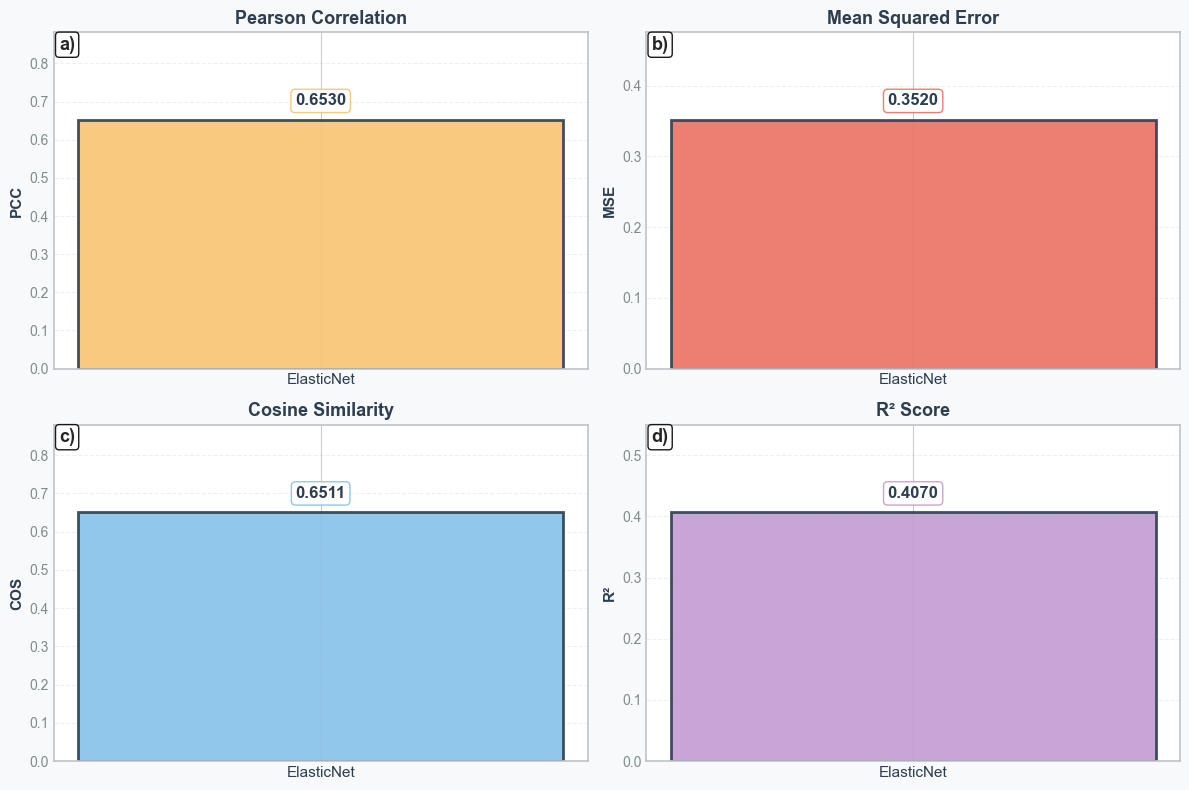

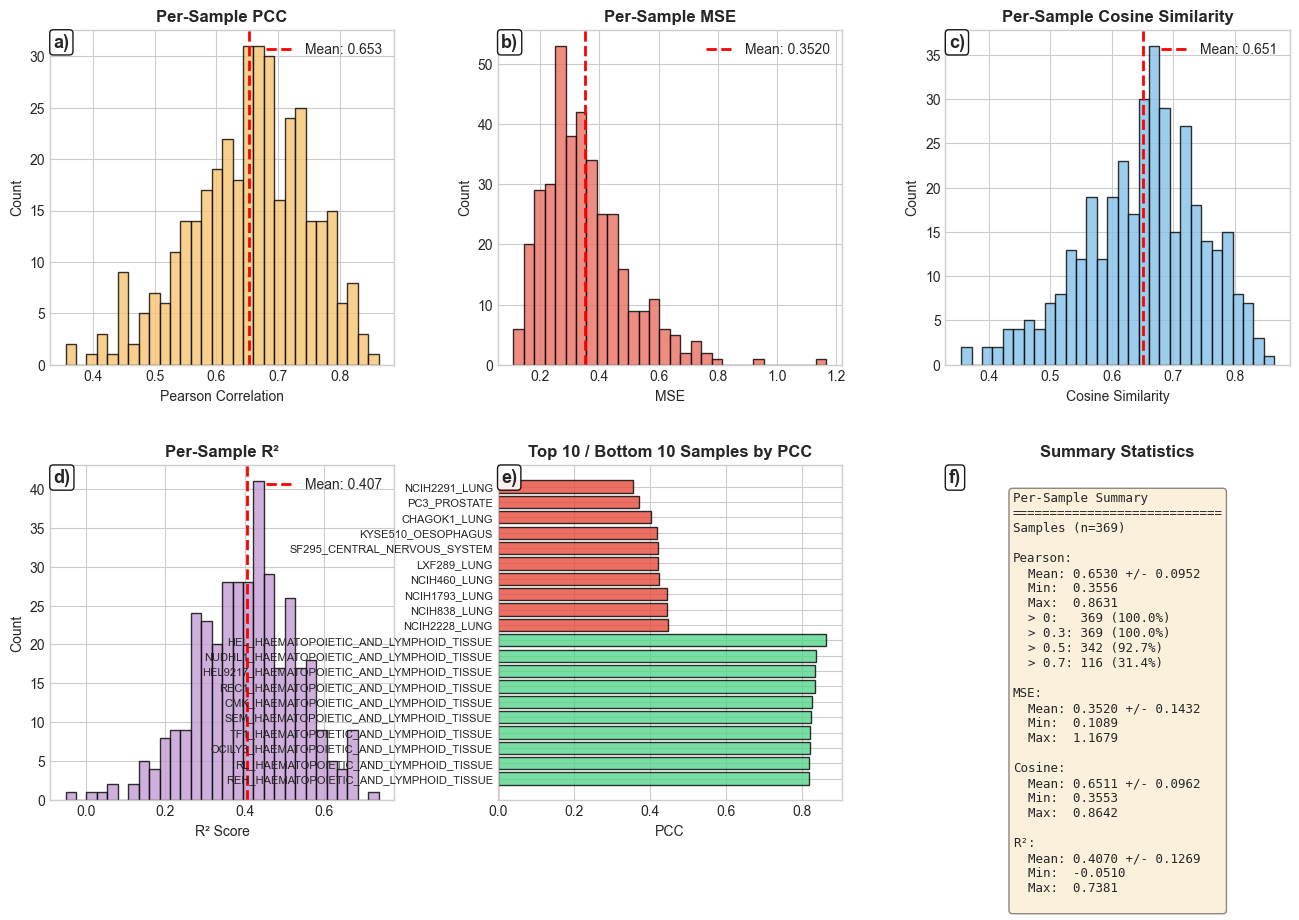

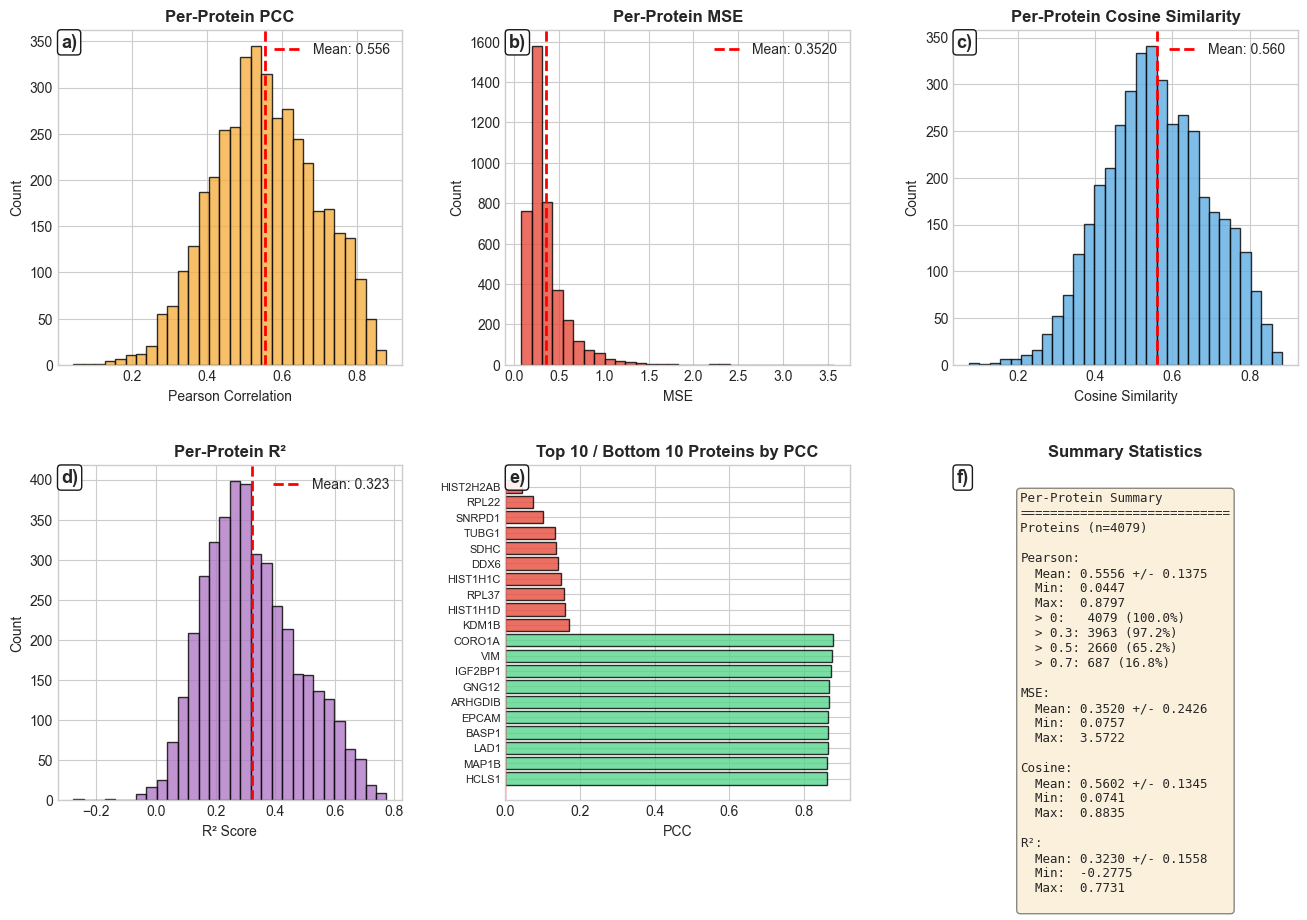

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from scipy.stats import pearsonr
from numpy.linalg import norm

# -----------------------------
# Helpers
# -----------------------------
def pearson_correlation(y_true, y_pred):
    if len(y_true) <= 1:
        return np.nan
    if np.std(y_true) == 0 or np.std(y_pred) == 0:
        return np.nan
    try:
        return pearsonr(y_true, y_pred)[0]
    except Exception:
        return np.nan

def cosine_similarity_metric(y_true, y_pred):
    if len(y_true) == 0:
        return np.nan
    denom = norm(y_true) * norm(y_pred)
    if denom == 0:
        return np.nan
    return np.dot(y_true, y_pred) / denom

def mse_metric(y_true, y_pred):
    if len(y_true) == 0:
        return np.nan
    return np.mean((y_true - y_pred) ** 2)

def _safe_r2(y_true, y_pred):
    if len(y_true) <= 1:
        return np.nan
    try:
        return r2_score(y_true, y_pred)
    except Exception:
        return np.nan

def _clean_pair(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = ~(np.isnan(y_true) | np.isnan(y_pred))
    return y_true[mask], y_pred[mask]

def _compute_metric_row(y_true, y_pred):
    y_true, y_pred = _clean_pair(y_true, y_pred)
    if len(y_true) <= 1:
        return None
    return {
        "pearson": pearson_correlation(y_true, y_pred),
        "mse": mse_metric(y_true, y_pred),
        "cosine": cosine_similarity_metric(y_true, y_pred),
        "r2": _safe_r2(y_true, y_pred),
    }

def _add_panel_label(ax, label):
    ax.text(
        0.01, 0.99, label,
        transform=ax.transAxes,
        fontsize=13,
        fontweight="bold",
        va="top",
        ha="left",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="black", alpha=0.9),
    )

def _get_group_colors(group):
    if group == "proteins":
        return {
            "pearson": "#F5B041",
            "mse": "#E74C3C",
            "cosine": "#5DADE2",
            "r2": "#AF7AC5",
        }
    elif group == "samples":
        return {
            "pearson": "#F8C471",
            "mse": "#EC7063",
            "cosine": "#85C1E9",
            "r2": "#C39BD3",
        }
    else:
        raise ValueError("group must be either 'samples' or 'proteins'")

def _plot_metric_hist(ax, values, title, xlabel, color, fmt=".3f", panel_label=None):
    values = pd.Series(values).dropna()

    ax.set_facecolor("#FFFFFF")
    if len(values) > 0:
        ax.hist(values, bins=30, color=color, edgecolor="black", alpha=0.8)
        mean_val = values.mean()
        if np.isfinite(mean_val):
            ax.axvline(mean_val, color="red", linestyle="--", linewidth=2, label=f"Mean: {mean_val:{fmt}}")
            ax.legend(loc="upper right")
    else:
        ax.text(0.5, 0.5, "No valid values", ha="center", va="center", transform=ax.transAxes)

    ax.set_xlabel(xlabel, fontsize=10)
    ax.set_ylabel("Count", fontsize=10)
    ax.set_title(title, fontsize=12, fontweight="bold")

    if panel_label is not None:
        _add_panel_label(ax, panel_label)

# -----------------------------
# Build detailed tables from combined_df
# -----------------------------
def compute_detailed_tables_from_combined(
    combined_df,
    sample_col="LOO sample",
    protein_col="protein",
    true_col="true",
    pred_col="predicted",
):
    required_cols = [sample_col, protein_col, true_col, pred_col]
    missing = [c for c in required_cols if c not in combined_df.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    df = combined_df[[sample_col, protein_col, true_col, pred_col]].copy()
    df[true_col] = pd.to_numeric(df[true_col], errors="coerce")
    df[pred_col] = pd.to_numeric(df[pred_col], errors="coerce")

    # Per-sample metrics (across proteins)
    per_sample = {
        "sample": [],
        "pearson": [],
        "mse": [],
        "cosine": [],
        "r2": [],
    }

    for sample, g in df.groupby(sample_col):
        row = _compute_metric_row(g[true_col].values, g[pred_col].values)
        if row is not None:
            per_sample["sample"].append(sample)
            per_sample["pearson"].append(row["pearson"])
            per_sample["mse"].append(row["mse"])
            per_sample["cosine"].append(row["cosine"])
            per_sample["r2"].append(row["r2"])

    per_sample_df = pd.DataFrame(per_sample).sort_values("pearson", ascending=False, na_position="last")

    # Per-protein metrics (across samples)
    per_protein = {
        "protein": [],
        "pearson": [],
        "mse": [],
        "cosine": [],
        "r2": [],
    }

    for protein, g in df.groupby(protein_col):
        row = _compute_metric_row(g[true_col].values, g[pred_col].values)
        if row is not None:
            per_protein["protein"].append(protein)
            per_protein["pearson"].append(row["pearson"])
            per_protein["mse"].append(row["mse"])
            per_protein["cosine"].append(row["cosine"])
            per_protein["r2"].append(row["r2"])

    per_protein_df = pd.DataFrame(per_protein).sort_values("pearson", ascending=False, na_position="last")

    top_10_samples = per_sample_df.sort_values("pearson", ascending=False, na_position="last").head(10)
    bottom_10_samples = per_sample_df.sort_values("pearson", ascending=True, na_position="last").head(10)

    top_10_proteins = per_protein_df.sort_values("pearson", ascending=False, na_position="last").head(10)
    bottom_10_proteins = per_protein_df.sort_values("pearson", ascending=True, na_position="last").head(10)

    return (
        per_sample_df,
        per_protein_df,
        top_10_samples,
        bottom_10_samples,
        top_10_proteins,
        bottom_10_proteins,
    )

# -----------------------------
# Mean metrics from combined_df
# -----------------------------
def compute_mean_metrics_from_combined(
    combined_df,
    group="samples",
    sample_col="LOO sample",
    protein_col="protein",
    true_col="true",
    pred_col="predicted",
):
    if group not in {"samples", "proteins"}:
        raise ValueError("group must be either 'samples' or 'proteins'")

    (
        per_sample_df,
        per_protein_df,
        _,
        _,
        _,
        _,
    ) = compute_detailed_tables_from_combined(
        combined_df,
        sample_col=sample_col,
        protein_col=protein_col,
        true_col=true_col,
        pred_col=pred_col,
    )

    df = per_sample_df if group == "samples" else per_protein_df

    return {
        "Pearson": np.nanmean(df["pearson"]) if len(df) else np.nan,
        "MSE": np.nanmean(df["mse"]) if len(df) else np.nan,
        "Cosine": np.nanmean(df["cosine"]) if len(df) else np.nan,
        "R2": np.nanmean(df["r2"]) if len(df) else np.nan,
    }

# -----------------------------
# Overall bar plots
# -----------------------------
def plot_overall_bar(mean_metrics, out_path=None, label="ElasticNet", group="proteins"):
    plt.style.use("seaborn-v0_8-whitegrid")
    colors = _get_group_colors(group)

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    fig.patch.set_facecolor("#F8F9FA")

    plots = [
        ("Pearson Correlation", "PCC", mean_metrics.get("Pearson", np.nan), colors["pearson"], "a)"),
        ("Mean Squared Error", "MSE", mean_metrics.get("MSE", np.nan), colors["mse"], "b)"),
        ("Cosine Similarity", "COS", mean_metrics.get("Cosine", np.nan), colors["cosine"], "c)"),
        ("R² Score", "R²", mean_metrics.get("R2", np.nan), colors["r2"], "d)"),
    ]

    for ax, (title, ylabel, value, color, panel_label) in zip(axes.flatten(), plots):
        ax.set_facecolor("#FFFFFF")

        if np.isfinite(value):
            bar = ax.bar(
                [label], [value],
                color=color, width=0.6,
                edgecolor="#2C3E50", linewidth=2, alpha=0.9
            )

            for rect in bar:
                height = rect.get_height()
                ax.annotate(
                    f"{value:.4f}",
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 8 if value >= 0 else -18),
                    textcoords="offset points",
                    ha="center",
                    va="bottom" if value >= 0 else "top",
                    fontsize=12,
                    fontweight="bold",
                    color="#2C3E50",
                    bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=color, alpha=0.9),
                )

            if value >= 0:
                ax.set_ylim(0, value * 1.35 if value != 0 else 1)
            else:
                ax.set_ylim(value * 1.35, abs(value) * 0.35)
        else:
            ax.text(0.5, 0.5, "No valid values", ha="center", va="center", transform=ax.transAxes)

        ax.set_title(title, fontsize=13, fontweight="bold", color="#2C3E50")
        ax.set_ylabel(ylabel, fontsize=11, fontweight="bold", color="#2C3E50")
        ax.tick_params(axis="x", labelsize=11, colors="#2C3E50")
        ax.tick_params(axis="y", labelsize=10, colors="#7F8C8D")
        ax.yaxis.grid(True, linestyle="--", alpha=0.3)
        ax.set_axisbelow(True)

        for spine in ax.spines.values():
            spine.set_color("#BDC3C7")
            spine.set_linewidth(1.2)

        _add_panel_label(ax, panel_label)

    plt.tight_layout()

    if out_path is not None:
        plt.savefig(out_path, dpi=200, bbox_inches="tight", facecolor=fig.get_facecolor())
        print(f"Saved: {out_path}")

    plt.show()

# -----------------------------
# Detailed 6-panel plots
# -----------------------------
def plot_detailed(per_sample_df=None, per_protein_df=None, group="samples", out_path=None):
    if group not in {"samples", "proteins"}:
        raise ValueError("group must be either 'samples' or 'proteins'")

    colors = _get_group_colors(group)

    fig = plt.figure(figsize=(16, 10))
    gs = fig.add_gridspec(2, 3, hspace=0.3, wspace=0.3)

    if group == "samples":
        if per_sample_df is None:
            raise ValueError("per_sample_df is required when group='samples'")

        df = per_sample_df.copy()

        ax1 = fig.add_subplot(gs[0, 0])
        _plot_metric_hist(ax1, df["pearson"], "Per-Sample PCC", "Pearson Correlation", colors["pearson"], panel_label="a)")

        ax2 = fig.add_subplot(gs[0, 1])
        _plot_metric_hist(ax2, df["mse"], "Per-Sample MSE", "MSE", colors["mse"], fmt=".4f", panel_label="b)")

        ax3 = fig.add_subplot(gs[0, 2])
        _plot_metric_hist(ax3, df["cosine"], "Per-Sample Cosine Similarity", "Cosine Similarity", colors["cosine"], panel_label="c)")

        ax4 = fig.add_subplot(gs[1, 0])
        _plot_metric_hist(ax4, df["r2"], "Per-Sample R²", "R² Score", colors["r2"], panel_label="d)")

        ax5 = fig.add_subplot(gs[1, 1])
        top_10 = df.sort_values("pearson", ascending=False, na_position="last").head(10).sort_values("pearson", ascending=True)
        bottom_10 = df.sort_values("pearson", ascending=True, na_position="last").head(10).sort_values("pearson", ascending=False)
        combined = pd.concat([top_10, bottom_10], axis=0)

        bar_colors = (["#58D68D"] * len(top_10)) + (["#E74C3C"] * len(bottom_10))
        y_pos = np.arange(len(combined))

        ax5.barh(y_pos, combined["pearson"].values, color=bar_colors, edgecolor="black", alpha=0.8)
        ax5.set_yticks(y_pos)
        ax5.set_yticklabels(combined["sample"].values, fontsize=8)
        ax5.axvline(0, color="red", linestyle="-", linewidth=1)
        ax5.set_xlabel("PCC", fontsize=10)
        ax5.set_title("Top 10 / Bottom 10 Samples by PCC", fontsize=12, fontweight="bold")
        _add_panel_label(ax5, "e)")

        ax6 = fig.add_subplot(gs[1, 2])
        ax6.axis("off")
        ax6.set_title("Summary Statistics", fontsize=12, fontweight="bold")
        _add_panel_label(ax6, "f)")

        n_samples = len(df)
        positive_pcc_count = (df["pearson"] > 0).sum()
        high_pcc_03 = (df["pearson"] > 0.3).sum()
        high_pcc_05 = (df["pearson"] > 0.5).sum()
        high_pcc_07 = (df["pearson"] > 0.7).sum()

        summary_text = f"""Per-Sample Summary
{'='*28}
Samples (n={n_samples})

Pearson:
  Mean: {df['pearson'].mean():.4f} +/- {df['pearson'].std():.4f}
  Min:  {df['pearson'].min():.4f}
  Max:  {df['pearson'].max():.4f}
  > 0:   {positive_pcc_count} ({(positive_pcc_count/n_samples*100) if n_samples else np.nan:.1f}%)
  > 0.3: {high_pcc_03} ({(high_pcc_03/n_samples*100) if n_samples else np.nan:.1f}%)
  > 0.5: {high_pcc_05} ({(high_pcc_05/n_samples*100) if n_samples else np.nan:.1f}%)
  > 0.7: {high_pcc_07} ({(high_pcc_07/n_samples*100) if n_samples else np.nan:.1f}%)

MSE:
  Mean: {df['mse'].mean():.4f} +/- {df['mse'].std():.4f}
  Min:  {df['mse'].min():.4f}
  Max:  {df['mse'].max():.4f}

Cosine:
  Mean: {df['cosine'].mean():.4f} +/- {df['cosine'].std():.4f}
  Min:  {df['cosine'].min():.4f}
  Max:  {df['cosine'].max():.4f}

R²:
  Mean: {df['r2'].mean():.4f} +/- {df['r2'].std():.4f}
  Min:  {df['r2'].min():.4f}
  Max:  {df['r2'].max():.4f}
"""
        ax6.text(
            0.5, 0.92, summary_text,
            transform=ax6.transAxes,
            fontsize=9,
            va="top",
            ha="center",
            multialignment="left",
            fontfamily="monospace",
            bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.45),
        )

    else:
        if per_protein_df is None:
            raise ValueError("per_protein_df is required when group='proteins'")

        df = per_protein_df.copy()

        ax1 = fig.add_subplot(gs[0, 0])
        _plot_metric_hist(ax1, df["pearson"], "Per-Protein PCC", "Pearson Correlation", colors["pearson"], panel_label="a)")

        ax2 = fig.add_subplot(gs[0, 1])
        _plot_metric_hist(ax2, df["mse"], "Per-Protein MSE", "MSE", colors["mse"], fmt=".4f", panel_label="b)")

        ax3 = fig.add_subplot(gs[0, 2])
        _plot_metric_hist(ax3, df["cosine"], "Per-Protein Cosine Similarity", "Cosine Similarity", colors["cosine"], panel_label="c)")

        ax4 = fig.add_subplot(gs[1, 0])
        _plot_metric_hist(ax4, df["r2"], "Per-Protein R²", "R² Score", colors["r2"], panel_label="d)")

        ax5 = fig.add_subplot(gs[1, 1])
        top_10 = df.sort_values("pearson", ascending=False, na_position="last").head(10).sort_values("pearson", ascending=True)
        bottom_10 = df.sort_values("pearson", ascending=True, na_position="last").head(10).sort_values("pearson", ascending=False)
        combined = pd.concat([top_10, bottom_10], axis=0)

        bar_colors = (["#58D68D"] * len(top_10)) + (["#E74C3C"] * len(bottom_10))
        y_pos = np.arange(len(combined))

        ax5.barh(y_pos, combined["pearson"].values, color=bar_colors, edgecolor="black", alpha=0.8)
        ax5.set_yticks(y_pos)
        ax5.set_yticklabels(combined["protein"].values, fontsize=8)
        ax5.axvline(0, color="red", linestyle="-", linewidth=1)
        ax5.set_xlabel("PCC", fontsize=10)
        ax5.set_title("Top 10 / Bottom 10 Proteins by PCC", fontsize=12, fontweight="bold")
        _add_panel_label(ax5, "e)")

        ax6 = fig.add_subplot(gs[1, 2])
        ax6.axis("off")
        ax6.set_title("Summary Statistics", fontsize=12, fontweight="bold")
        _add_panel_label(ax6, "f)")

        n_proteins = len(df)
        positive_pcc_count = (df["pearson"] > 0).sum()
        high_pcc_03 = (df["pearson"] > 0.3).sum()
        high_pcc_05 = (df["pearson"] > 0.5).sum()
        high_pcc_07 = (df["pearson"] > 0.7).sum()

        summary_text = f"""Per-Protein Summary
{'='*28}
Proteins (n={n_proteins})

Pearson:
  Mean: {df['pearson'].mean():.4f} +/- {df['pearson'].std():.4f}
  Min:  {df['pearson'].min():.4f}
  Max:  {df['pearson'].max():.4f}
  > 0:   {positive_pcc_count} ({(positive_pcc_count/n_proteins*100) if n_proteins else np.nan:.1f}%)
  > 0.3: {high_pcc_03} ({(high_pcc_03/n_proteins*100) if n_proteins else np.nan:.1f}%)
  > 0.5: {high_pcc_05} ({(high_pcc_05/n_proteins*100) if n_proteins else np.nan:.1f}%)
  > 0.7: {high_pcc_07} ({(high_pcc_07/n_proteins*100) if n_proteins else np.nan:.1f}%)

MSE:
  Mean: {df['mse'].mean():.4f} +/- {df['mse'].std():.4f}
  Min:  {df['mse'].min():.4f}
  Max:  {df['mse'].max():.4f}

Cosine:
  Mean: {df['cosine'].mean():.4f} +/- {df['cosine'].std():.4f}
  Min:  {df['cosine'].min():.4f}
  Max:  {df['cosine'].max():.4f}

R²:
  Mean: {df['r2'].mean():.4f} +/- {df['r2'].std():.4f}
  Min:  {df['r2'].min():.4f}
  Max:  {df['r2'].max():.4f}
"""
        ax6.text(
            0.5, 0.92, summary_text,
            transform=ax6.transAxes,
            fontsize=9,
            va="top",
            ha="center",
            multialignment="left",
            fontfamily="monospace",
            bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.45),
        )

    plt.tight_layout()

    if out_path is not None:
        plt.savefig(out_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {out_path}")

    plt.show()

# -----------------------------
# Run everything from combined_df
# -----------------------------
(
    per_sample_df,
    per_protein_df,
    top_10_samples,
    bottom_10_samples,
    top_10_proteins,
    bottom_10_proteins,
) = compute_detailed_tables_from_combined(combined_df)

mean_metrics_samples = compute_mean_metrics_from_combined(combined_df, group="samples")
mean_metrics_proteins = compute_mean_metrics_from_combined(combined_df, group="proteins")

print("Per-sample mean metrics:")
print(mean_metrics_samples)
print("\nPer-protein mean metrics:")
print(mean_metrics_proteins)

# Overall bars
plot_overall_bar(mean_metrics_samples, group="samples", label="ElasticNet")

# Detailed panels
plot_detailed(per_sample_df=per_sample_df, group="samples")
plot_detailed(per_protein_df=per_protein_df, group="proteins")

In [3]:
# Non-finite overview (NaN / +Inf / -Inf) for combined_df

df = combined_df  # already loaded above
n_rows, n_cols = df.shape

# split columns
numeric_cols = df.select_dtypes(include=[np.number]).columns
non_numeric_cols = df.columns.difference(numeric_cols)

# per-column counts
nan_counts = df.isna().sum()

# ±Inf only make sense for numeric columns
if len(numeric_cols) > 0:
    posinf_counts_num = pd.Series(
        np.isposinf(df[numeric_cols].to_numpy()).sum(axis=0), index=numeric_cols, dtype="int64"
    )
    neginf_counts_num = pd.Series(
        np.isneginf(df[numeric_cols].to_numpy()).sum(axis=0), index=numeric_cols, dtype="int64"
    )
else:
    posinf_counts_num = pd.Series(dtype="int64")
    neginf_counts_num = pd.Series(dtype="int64")

# align to all columns (0 for non-numeric)
posinf_counts = pd.Series(0, index=df.columns, dtype="int64")
neginf_counts = pd.Series(0, index=df.columns, dtype="int64")
posinf_counts.loc[posinf_counts_num.index] = posinf_counts_num
neginf_counts.loc[neginf_counts_num.index] = neginf_counts_num

summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_nan": nan_counts.astype("int64"),
    "n_posinf": posinf_counts,
    "n_neginf": neginf_counts,
})
summary["n_inf"] = summary["n_posinf"] + summary["n_neginf"]
summary["n_nonfinite"] = summary["n_nan"] + summary["n_inf"]
summary["pct_nonfinite"] = (summary["n_nonfinite"] / max(n_rows, 1)) * 100

# row-level stats
nan_any_row = df.isna().any(axis=1).to_numpy()

if len(numeric_cols) > 0:
    inf_mask = np.isinf(df[numeric_cols].to_numpy())
    inf_any_row = inf_mask.any(axis=1)
else:
    inf_any_row = np.zeros(n_rows, dtype=bool)

nonfinite_any_row = nan_any_row | inf_any_row

print(f"Rows: {n_rows}  |  Columns: {n_cols} (numeric: {len(numeric_cols)}, non-numeric: {len(non_numeric_cols)})")
print(f"Rows with any NaN: {int(nan_any_row.sum())}")
print(f"Rows with any ±Inf (numeric only): {int(inf_any_row.sum())}")
print(f"Rows with any non-finite (NaN or ±Inf): {int(nonfinite_any_row.sum())}\n")

# show columns with most issues first
summary_sorted = summary.sort_values("n_nonfinite", ascending=False)

# pretty display
display(
    summary_sorted.style
        .format({"pct_nonfinite": "{:.2f}%", "n_nan": "{:d}", "n_posinf": "{:d}", "n_neginf": "{:d}", "n_inf": "{:d}", "n_nonfinite": "{:d}"})
        .bar(subset=["n_nonfinite"], color="#FFA07A")
        .bar(subset=["n_nan"], color="#FFDAB9")
        .bar(subset=["n_inf"], color="#FFC0CB")
)

# optional: quick list of the top 10 worst columns
print("\nTop 10 columns by non-finite values:")
display(summary_sorted.head(10)[["dtype","n_nonfinite","n_nan","n_inf","pct_nonfinite"]])


Rows: 506637  |  Columns: 4 (numeric: 2, non-numeric: 2)
Rows with any NaN: 0
Rows with any ±Inf (numeric only): 0
Rows with any non-finite (NaN or ±Inf): 0



,dtype,n_nan,n_posinf,n_neginf,n_inf,n_nonfinite,pct_nonfinite
protein,object,0,0,0,0,0,0.00%
LOO sample,object,0,0,0,0,0,0.00%
true,float64,0,0,0,0,0,0.00%
predicted,float64,0,0,0,0,0,0.00%



Top 10 columns by non-finite values:


,dtype,n_nonfinite,n_nan,n_inf,pct_nonfinite
protein,object,0,0,0,0.0
LOO sample,object,0,0,0,0.0
true,float64,0,0,0,0.0
predicted,float64,0,0,0,0.0


In [4]:

df = combined_df.copy()

# choose the sample column
sample_col = 'LOO sample' if 'LOO sample' in df.columns else 'sample'

# keep only numeric/finite true & predicted
df['true'] = pd.to_numeric(df['true'], errors='coerce')
df['predicted'] = pd.to_numeric(df['predicted'], errors='coerce')
df = df.replace([np.inf, -np.inf], np.nan)

# mask of rows with finite true & predicted
row_ok = df[['true', 'predicted']].notna().all(axis=1)

# A) proteins present after dropping all non-finite rows (≥1 valid row remains)
n_proteins_total = df['protein'].nunique()
n_proteins_after_drop = df.loc[row_ok, 'protein'].nunique()

print(f"Unique proteins (total): {n_proteins_total}")
print(f"Unique proteins with at least one valid row after removing NaNs/±Inf: {n_proteins_after_drop}")

# B) proteins complete across *all* their rows (no NaN/±Inf anywhere)
protein_complete = (
    df.groupby('protein')[['true', 'predicted']]
      .apply(lambda g: g.notna().all().all())
)
n_proteins_complete = int(protein_complete.sum())
print(f"Proteins complete across all rows (no NaN/±Inf in true/predicted): {n_proteins_complete}")

# C) per-sample: how many proteins remain after removing NaNs/±Inf (counts of valid rows)
per_sample_counts = (
    df.groupby(sample_col)
      .apply(lambda g: g[['true','predicted']].notna().all(axis=1).sum())
      .reset_index(name='n_proteins_remaining')
)

print("\nPer-sample proteins remaining (first 10 rows):")
display(per_sample_counts.head(10))

print("\nPer-sample summary:")
print(
    per_sample_counts['n_proteins_remaining']
      .agg(['min','median','max'])
      .rename({'min':'min', 'median':'median', 'max':'max'})
      .to_string()
)


Unique proteins (total): 1373
Unique proteins with at least one valid row after removing NaNs/±Inf: 1373
Proteins complete across all rows (no NaN/±Inf in true/predicted): 1373

Per-sample proteins remaining (first 10 rows):


,LOO sample,n_proteins_remaining
0,22RV1_PROSTATE,1373
1,697_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,1373
2,769P_KIDNEY,1373
3,786O_KIDNEY,1373
4,8305C_THYROID,1373
5,8505C_THYROID,1373
6,A101D_SKIN,1373
7,A172_CENTRAL_NERVOUS_SYSTEM,1373
8,A204_SOFT_TISSUE,1373
9,A2058_SKIN,1373



Per-sample summary:
min       1373.0
median    1373.0
max       1373.0


In [5]:
# Clean combined_df by removing entire proteins that contain any NaN/±Inf in true/predicted
df = combined_df.copy()

# 1) Coerce to numeric and turn ±Inf into NaN
df["true"] = pd.to_numeric(df["true"], errors="coerce")
df["predicted"] = pd.to_numeric(df["predicted"], errors="coerce")
df = df.replace([np.inf, -np.inf], np.nan)

# 2) Which proteins are COMPLETE (no NaN in any of their rows for true/predicted)?
protein_complete = (
    df.groupby("protein")[["true", "predicted"]]
      .apply(lambda g: g.notna().all().all())
)
kept_proteins = protein_complete[protein_complete].index

# 3) Filter to the cleaned dataset
combined_df_clean = df[df["protein"].isin(kept_proteins)].copy()

# 4) New NaN/Inf overview (should be zero for true/predicted)
n_rows_before = len(df)
n_rows_after  = len(combined_df_clean)
n_proteins_before = df["protein"].nunique()
n_proteins_after  = combined_df_clean["protein"].nunique()

nan_true_before = df["true"].isna().sum()
nan_pred_before = df["predicted"].isna().sum()
nan_true_after  = combined_df_clean["true"].isna().sum()
nan_pred_after  = combined_df_clean["predicted"].isna().sum()

print(f"Rows before:  {n_rows_before:,}   | proteins before:  {n_proteins_before:,}")
print(f"Rows after:   {n_rows_after:,}    | proteins after:   {n_proteins_after:,}")
print(f"Proteins removed: {n_proteins_before - n_proteins_after:,}")

print("\nNaN check (true/predicted):")
print(f"  Before  -> true: {nan_true_before:,}  | predicted: {nan_pred_before:,}")
print(f"  After   -> true: {nan_true_after:,}   | predicted: {nan_pred_after:,}")

# Optional: quick all-column non-finite check on the cleaned frame
numeric_cols = combined_df_clean.select_dtypes(include=[np.number]).columns
rows_with_any_nan = combined_df_clean.isna().any(axis=1).sum()
rows_with_any_inf = np.isinf(combined_df_clean[numeric_cols].to_numpy()).any(axis=1).sum() if len(numeric_cols) else 0
print(f"\nRows with any NaN (any column) in cleaned df: {rows_with_any_nan:,}")
print(f"Rows with any ±Inf (numeric cols) in cleaned df: {rows_with_any_inf:,}")

print("\nFinal cleaned shape:", combined_df_clean.shape)

combined_df = combined_df_clean


Rows before:  506,637   | proteins before:  1,373
Rows after:   506,637    | proteins after:   1,373
Proteins removed: 0

NaN check (true/predicted):
  Before  -> true: 0  | predicted: 0
  After   -> true: 0   | predicted: 0

Rows with any NaN (any column) in cleaned df: 0
Rows with any ±Inf (numeric cols) in cleaned df: 0

Final cleaned shape: (506637, 4)


In [29]:
# scTranslator-style per-sample min–max normalization for a long DataFrame
# expected columns in `combined_df`: ["protein", "LOO sample", "true", "predicted"]

EPS = 1e-8  # lower bound in the target scale

# --- sanity checks
required_cols = {"protein", "LOO sample", "true", "predicted"}
missing = required_cols - set(combined_df.columns)
if missing:
    raise ValueError(f"combined_df is missing required columns: {sorted(missing)}")

df = combined_df.copy()

# ensure numeric
df["true"] = pd.to_numeric(df["true"], errors="coerce")
df["predicted"] = pd.to_numeric(df["predicted"], errors="coerce")

# compute truth-based min/max per sample (LOO sample)
g = df.groupby("LOO sample", observed=True)["true"]
mins = g.min().rename("tmin")
maxs = g.max().rename("tmax")
mm = pd.concat([mins, maxs], axis=1)

# merge back
df = df.merge(mm, left_on="LOO sample", right_index=True, how="left")

# scale function using truth min/max for the sample
denom = (df["tmax"] - df["tmin"]).to_numpy()
denom = np.where(denom == 0, np.nan, denom)  # mark degenerate samples

def scale_series(x, tmin, denom):
    out = EPS + (x.to_numpy() - tmin.to_numpy()) / denom * (1.0 - EPS)
    # if denom is nan (constant truth vector), set all to EPS
    out = np.where(np.isnan(out), EPS, out)
    return pd.Series(out, index=x.index, dtype="float64")

df["true_mm"] = scale_series(df["true"], df["tmin"], denom)
df["pred_mm"] = scale_series(df["predicted"], df["tmin"], denom)

# clip to be extra-safe against tiny floating drift
df["true_mm"]  = df["true_mm"].clip(lower=EPS, upper=1.0)
df["pred_mm"]  = df["pred_mm"].clip(lower=EPS, upper=1.0)

# quick validation
print("Ranges after scaling:")
print("  true_mm :", float(df["true_mm"].min()), "→", float(df["true_mm"].max()))
print("  pred_mm :", float(df["pred_mm"].min()), "→", float(df["pred_mm"].max()))

# OPTIONAL: per-protein Pearson r on the min–max scale
# (pivot to samples × proteins, then correlate column-wise)
want_metrics = True
if want_metrics:
    t_mat = df.pivot(index="LOO sample", columns="protein", values="true_mm")
    p_mat = df.pivot(index="LOO sample", columns="protein", values="pred_mm")

    # align columns just in case
    common = t_mat.columns.intersection(p_mat.columns)
    t_mat = t_mat[common]
    p_mat = p_mat[common]

    # vectorized Pearson r per protein
    t = t_mat.to_numpy(dtype=float)
    p = p_mat.to_numpy(dtype=float)

    # subtract means along samples
    t_z = t - np.nanmean(t, axis=0, keepdims=True)
    p_z = p - np.nanmean(p, axis=0, keepdims=True)

    num = np.nansum(t_z * p_z, axis=0)
    den = np.sqrt(np.nansum(t_z**2, axis=0) * np.nansum(p_z**2, axis=0))
    r = np.divide(num, den, out=np.full_like(num, np.nan, dtype=float), where=den!=0)

    per_protein_corr = pd.Series(r, index=common, name="pearson_r").sort_values(ascending=False)
    print("\nPer-protein Pearson r (first 10):")
    print(per_protein_corr.head(10))

# df now contains normalized columns:
#   - 'true_mm' : truth scaled to [1e-8, 1] per sample using truth min/max
#   - 'pred_mm' : predictions scaled with the SAME per-sample truth min/max
# You can use these to compare fairly with scTranslator outputs.


Ranges after scaling:
  true_mm : 1e-08 → 1.0
  pred_mm : 1e-08 → 1.0

Per-protein Pearson r (first 10):
protein
DDX1        0.928625
DDX3X       0.928589
DDX41       0.918868
EFTUD2      0.917345
AP2B1       0.914785
AIMP2       0.914425
EIF4A3      0.914001
CDK13       0.912936
EIF3A       0.912654
ATP6V1E1    0.912398
Name: pearson_r, dtype: float64


In [6]:

# Compute absolute and squared errors
combined_df['abs_error'] = (combined_df['true'] - combined_df['predicted']).abs()
combined_df['squared_error'] = (combined_df['true'] - combined_df['predicted'])**2
combined_df['rel_error']     = combined_df['abs_error'] / (combined_df['true'].abs() + eps)
# Add overall Pearson and cosine similarity as columns
corr = combined_df['true'].corr(combined_df['predicted'])
cos  = combined_df['true'].mul(combined_df['predicted']).sum() / ((combined_df['true'].pow(2).sum()**0.5) * (combined_df['predicted'].pow(2).sum()**0.5) + eps)
combined_df['pearson_corr'] = corr
combined_df['cosine_similarity'] = cos

combined_df.head()


,protein,LOO sample,true,predicted,abs_error,squared_error,rel_error,pearson_corr,cosine_similarity
0,A2M,MDAMB468_BREAST,-0.345562,-0.691980,0.346417,0.120005,1.002474,0.655874,0.58521
1,A2M,SH4_SKIN,1.642186,0.469850,1.172336,1.374372,0.713888,0.655874,0.58521
2,A2M,AU565_BREAST,-1.129114,-0.811306,0.317809,0.101002,0.281467,0.655874,0.58521
3,A2M,KMRC1_KIDNEY,1.493333,0.888209,0.605124,0.366175,0.405217,0.655874,0.58521
4,A2M,CAL51_BREAST,0.274652,0.562785,0.288132,0.083020,1.049080,0.655874,0.58521


##  Protein-wise analysis


Compute per-protein metrics

In [7]:

# Compute absolute and squared errors
combined_df['abs_error'] = (combined_df['true'] - combined_df['predicted']).abs()
combined_df['squared_error'] = (combined_df['true'] - combined_df['predicted'])**2
combined_df['rel_error']     = combined_df['abs_error'] / (combined_df['true'].abs() + eps)
# Add overall Pearson and cosine similarity as columns
corr = combined_df['true'].corr(combined_df['predicted'])
cos  = combined_df['true'].mul(combined_df['predicted']).sum() / ((combined_df['true'].pow(2).sum()**0.5) * (combined_df['predicted'].pow(2).sum()**0.5) + eps)
combined_df['pearson_corr'] = corr
combined_df['cosine_similarity'] = cos

combined_df.head()


,protein,LOO sample,true,predicted,abs_error,squared_error,rel_error,pearson_corr,cosine_similarity
0,A2M,MDAMB468_BREAST,-0.345562,-0.602695,0.257133,0.066117,0.744100,0.669992,0.670363
1,A2M,SH4_SKIN,1.642186,0.980278,0.661908,0.438122,0.403065,0.669992,0.670363
2,A2M,AU565_BREAST,-1.129114,-0.371104,0.758010,0.574579,0.671331,0.669992,0.670363
3,A2M,KMRC1_KIDNEY,1.493333,0.870634,0.622699,0.387754,0.416986,0.669992,0.670363
4,A2M,CAL51_BREAST,0.274652,0.220913,0.053739,0.002888,0.195662,0.669992,0.670363


R² by protein — summary:
count    1373.000000
mean        0.335345
std         0.158474
min        -0.068189
25%         0.216802
50%         0.316634
75%         0.439657
max         0.763107
Name: r2, dtype: float64


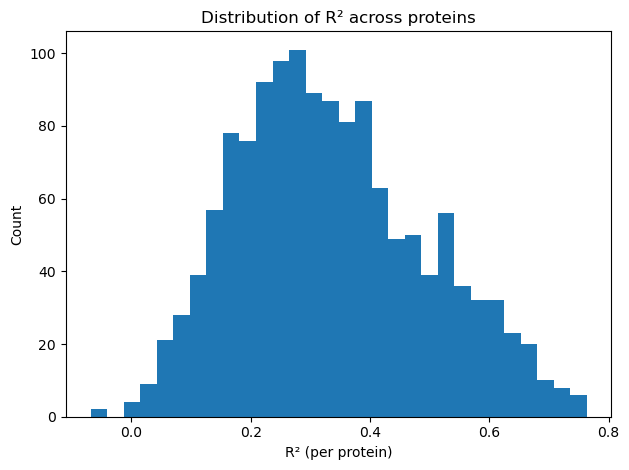


Top 10 proteins by R²:


,protein,r2
924,CORO1A,0.763107
716,CDH1,0.749666
280,ARHGDIB,0.749119
166,ALDH1A3,0.747603
433,BASP1,0.746846
133,AIM1,0.737060
1070,DCBLD2,0.731426
685,CD44,0.729500
216,ANXA2,0.728026
1296,EGFR,0.724905



Bottom 10 proteins by R²:


,protein,r2
752,CEP290,-0.068189
705,CDC42,-0.047371
864,CNOT11,-0.010754
826,CLEC16A,-0.001703
808,CIR1,-0.000089
802,CHTOP,0.003713
1125,DDX6,0.015196
384,ATP5SL,0.017856
191,ANAPC2,0.027687
1057,DARS,0.028413


In [8]:


# Per-protein R² (across all LOO samples for that protein)
def _r2_group(g):
    y, yhat = g['true'].values, g['predicted'].values
    return r2_score(y, yhat) if (len(y) > 1 and np.var(y) > 0) else np.nan

r2_by_protein = (combined_df
                 .groupby('protein', dropna=False)
                 .apply(_r2_group)
                 .rename('r2')
                 .reset_index())

print("R² by protein — summary:")
print(r2_by_protein['r2'].describe())

# Histogram
plt.figure()
plt.hist(r2_by_protein['r2'].dropna().values, bins=30)
plt.xlabel('R² (per protein)')
plt.ylabel('Count')
plt.title('Distribution of R² across proteins')
plt.tight_layout()
plt.show()

# Optional: extremes
print("\nTop 10 proteins by R²:")
display(r2_by_protein.sort_values('r2', ascending=False).head(10))
print("\nBottom 10 proteins by R²:")
display(r2_by_protein.sort_values('r2', ascending=True).head(10))



In [9]:
r2_by_protein['r2'].median()

0.31663404687457564

R² by sample — summary:
count    369.000000
mean       0.425010
std        0.116410
min        0.048913
25%        0.355997
50%        0.427873
75%        0.497280
max        0.728331
Name: r2, dtype: float64


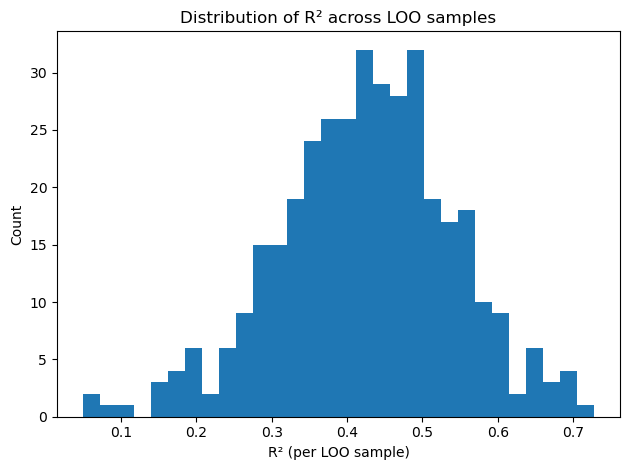


Top 10 LOO samples by R²:


,LOO sample,r2
97,HEL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.728331
294,SEM_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.699589
284,RL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.690675
41,CMK_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.689521
277,REC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.688564
278,REH_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.674597
200,MOLM16_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.671669
254,NUDHL1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.671319
324,SUDHL4_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.658453
325,SUDHL6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.657133



Bottom 10 LOO samples by R²:


,LOO sample,r2
182,LXF289_LUNG,0.048913
279,RERFLCMS_LUNG,0.059736
272,PC3_PROSTATE,0.087539
166,KYSE510_OESOPHAGUS,0.109662
135,JHOS2_OVARY,0.140968
232,NCIH2228_LUNG,0.152431
235,NCIH2291_LUNG,0.154190
213,NCIH1573_LUNG,0.162338
286,RPMI7951_SKIN,0.164000
220,NCIH1793_LUNG,0.171220


In [10]:

# Per-sample R² (across proteins within each LOO sample)
def _r2_sample_group(g):
    y, yhat = g['true'].values, g['predicted'].values
    return r2_score(y, yhat) if (len(y) > 1 and np.var(y) > 0) else np.nan

r2_by_sample = (combined_df
                .groupby('LOO sample', dropna=False)
                .apply(_r2_sample_group)
                .rename('r2')
                .reset_index())

print("R² by sample — summary:")
print(r2_by_sample['r2'].describe())

# Histogram
plt.figure()
plt.hist(r2_by_sample['r2'].dropna().values, bins=30)
plt.xlabel('R² (per LOO sample)')
plt.ylabel('Count')
plt.title('Distribution of R² across LOO samples')
plt.tight_layout()
plt.show()

# Optional: extremes
print("\nTop 10 LOO samples by R²:")
display(r2_by_sample.sort_values('r2', ascending=False).head(10))
print("\nBottom 10 LOO samples by R²:")
display(r2_by_sample.sort_values('r2', ascending=True).head(10))


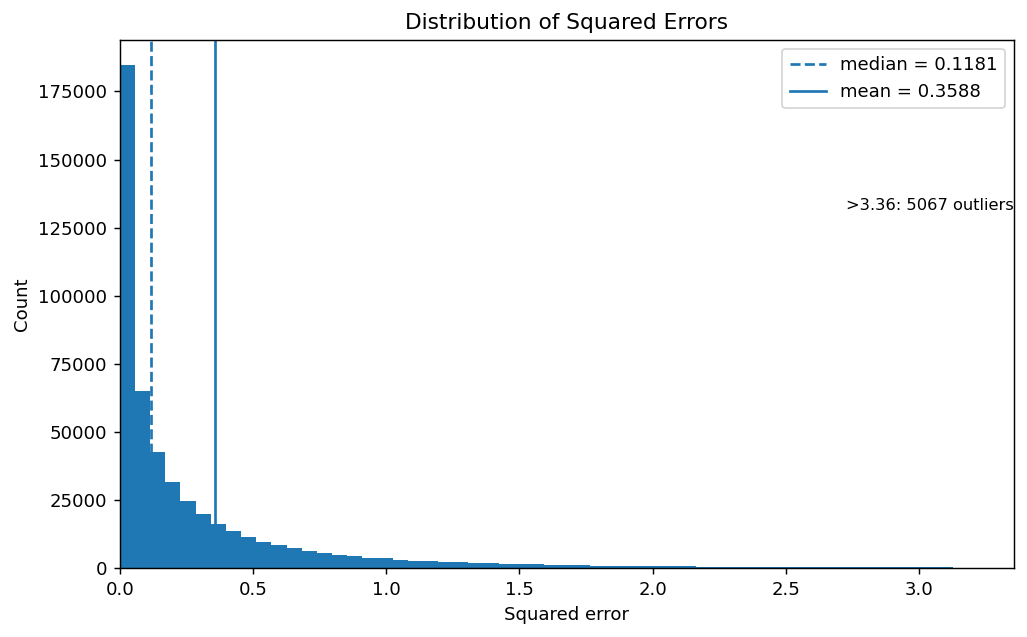

In [11]:
# pull clean squared errors
se = (pd.to_numeric(combined_df["squared_error"], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna())

# choose an x-axis cap (tweak if you like)
p95, p99, p999 = np.percentile(se, [95, 99, 99.9])
xmax = p99          # show up to the 99th percentile
tail_n = int((se > xmax).sum())

fig, ax = plt.subplots(figsize=(8, 5), dpi=130)

# histogram only for values within the cap
data_in = se[se <= xmax]
bins = np.linspace(0, xmax, 60)
ax.hist(data_in, bins=bins)

# annotate mean/median (only if they fall within the shown range)
mean_val = se.mean()
med_val  = se.median()
if med_val <= xmax:
    ax.axvline(med_val, linestyle="--", linewidth=1.5, label=f"median = {med_val:.4g}")
else:
    ax.text(xmax, ax.get_ylim()[1]*0.90, f"median = {med_val:.4g} (off-scale)",
            ha="right", va="top", fontsize=9)

if mean_val <= xmax:
    ax.axvline(mean_val, linestyle="-", linewidth=1.5, label=f"mean = {mean_val:.4g}")
else:
    ax.text(xmax, ax.get_ylim()[1]*0.80, f"mean = {mean_val:.4g} (off-scale)",
            ha="right", va="top", fontsize=9)

# x-axis limits and a note about the hidden tail
ax.set_xlim(0, xmax)
if tail_n > 0:
    ax.text(xmax, ax.get_ylim()[1]*0.70, f">{xmax:.3g}: {tail_n} outliers",
            ha="right", va="top", fontsize=9)

ax.set_title("Distribution of Squared Errors")
ax.set_xlabel("Squared error")
ax.set_ylabel("Count")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


In [12]:
# Per-sample metrics from combined_df → samples_df (369 rows expected)
eps = 1e-12

combined_df = combined_df.copy()

def _cos_sim(a, b):
    na = np.linalg.norm(a); nb = np.linalg.norm(b)
    denom = na * nb
    return float(np.dot(a, b) / denom) if denom > 0 else np.nan

# the column holding sample IDs (handles the space in "LOO sample")
sample_col = 'LOO sample' if 'LOO sample' in combined_df.columns else 'sample'

samples_df = (
    combined_df.groupby(sample_col, sort=False)
      .apply(lambda g: pd.Series({
          'n_proteins': len(g),
          'mae': g['abs_error'].mean(),
          'mse': g['squared_error'].mean(),
          'rmse': np.sqrt(g['squared_error'].mean()),
          'cosine_similarity': _cos_sim(g['true'].to_numpy(), g['predicted'].to_numpy()),
          'pearson_corr': g['true'].corr(g['predicted'])
      }))
      .reset_index()
      .rename(columns={sample_col: 'sample'})
)

samples_df.head()


,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr
0,MDAMB468_BREAST,1373.0,0.312111,0.181051,0.425501,0.656305,0.656367
1,SH4_SKIN,1373.0,0.289606,0.158111,0.397632,0.688734,0.688917
2,AU565_BREAST,1373.0,0.325269,0.191973,0.438148,0.751937,0.754397
3,KMRC1_KIDNEY,1373.0,0.329760,0.208096,0.456176,0.635337,0.627654
4,CAL51_BREAST,1373.0,0.273513,0.138587,0.372272,0.667046,0.665553


In [28]:
samples_df.sort_values('mse', ascending=False).head(20)

,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr,tissue
262,RCHACV_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,1373.0,0.936078,1.262994,1.123830,0.684626,0.672820,TISSUE
166,MOLM13_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,1373.0,0.762644,0.929427,0.964068,0.579443,0.572886,TISSUE
212,CAKI1_KIDNEY,1373.0,0.689698,0.829775,0.910920,0.720991,0.720582,KIDNEY
88,NCIH1573_LUNG,1373.0,0.672289,0.785754,0.886428,0.460017,0.477878,LUNG
181,KNS81_CENTRAL_NERVOUS_SYSTEM,1373.0,0.706778,0.779130,0.882683,0.632570,0.640545,SYSTEM
170,IM95_STOMACH,1373.0,0.690297,0.770382,0.877714,0.675161,0.685987,STOMACH
240,KNS42_CENTRAL_NERVOUS_SYSTEM,1373.0,0.687540,0.758513,0.870926,0.521596,0.522696,SYSTEM
271,MONOMAC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,1373.0,0.698830,0.729672,0.854209,0.684091,0.692630,TISSUE
183,TE10_OESOPHAGUS,1373.0,0.670032,0.724461,0.851153,0.785785,0.777862,OESOPHAGUS
232,JM1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,1373.0,0.695212,0.715443,0.845838,0.746632,0.738231,TISSUE


In [13]:
#  tissue counts from samples_df 

min_n = 18 # threshold for "low-representation" tissues

# Tissue is the suffix after the last underscore
samples_df = samples_df.copy()
samples_df["tissue"] = samples_df["sample"].astype(str).str.rsplit("_", n=1).str[-1]

# Count unique samples per tissue
tissue_counts = (
    samples_df.drop_duplicates("sample")
              .groupby("tissue")["sample"]
              .nunique()
              .sort_values()
)

low_tissues = tissue_counts[tissue_counts <= min_n]

print(f"Total tissues: {tissue_counts.size}")
print(f"Tissues with <= {min_n} samples:")
if low_tissues.empty:
    print("  (none)")
else:
    # pretty print as two columns
    print(low_tissues.to_string())


Total tissues: 19
Tissues with <= 18 samples:
tissue
GANGLIA         1
THYROID         2
PLEURA          2
PROSTATE        4
BONE            7
KIDNEY         11
SYSTEM         13
ENDOMETRIUM    14
LIVER          14
STOMACH        14
OESOPHAGUS     14
OVARY          17


In [16]:
#  filter combined_df by tissue representation 
n = 18  # set the threshold here

# Reuse tissue mapping from Cell 1 (samples_df already has a 'tissue' column)
tissue_sample_counts = (
    samples_df.drop_duplicates("sample")
              .groupby("tissue")["sample"]
              .nunique()
)

low_tissues = set(tissue_sample_counts[tissue_sample_counts < n].index)

# All samples that belong to low-representation tissues
low_tissue_samples = set(
    samples_df.loc[samples_df["tissue"].isin(low_tissues), "sample"].unique()
)

# combined_df may name the sample column as 'LOO_sample' or 'LOO sample'—we handle both.
sample_col = "LOO_sample" if "LOO_sample" in combined_df.columns else (
    "LOO sample" if "LOO sample" in combined_df.columns else "sample"
)

before = len(combined_df)
clean = combined_df.loc[~combined_df[sample_col].isin(low_tissue_samples)].copy()
after = len(clean)

print(f"Threshold n = {n}")
print(f"Low-representation tissues ({len(low_tissues)}): {sorted(low_tissues) if low_tissues else 'none'}")
print(f"Removed {before - after} rows; kept {after} rows.")


Threshold n = 18
Low-representation tissues (12): ['BONE', 'ENDOMETRIUM', 'GANGLIA', 'KIDNEY', 'LIVER', 'OESOPHAGUS', 'OVARY', 'PLEURA', 'PROSTATE', 'STOMACH', 'SYSTEM', 'THYROID']
Removed 155149 rows; kept 351488 rows.


In [17]:
def _cos_sim(a, b):
    na = np.linalg.norm(a); nb = np.linalg.norm(b)
    denom = na * nb
    return float(np.dot(a, b) / denom) if denom > 0 else np.nan

per_protein = (
    clean.groupby('protein', sort=False)
    .apply(lambda g: pd.Series({
        'n_samples': len(g),
        'mse': g['squared_error'].mean(),
        'cosine_similarity': _cos_sim(g['true'].to_numpy(), g['predicted'].to_numpy()),
        'pearson_corr': g['true'].corr(g['predicted'])
    }))
    .reset_index()
)

### Top 100 proteins by mean squared error-cosine similarity-pearson correlation

In [18]:
# Per-protein ranking tables: MAE, cosine similarity, Pearson correlation


top100_mae     = per_protein.sort_values('mse', ascending=True).head(100)         # lower is better
top100_cosine  = per_protein.sort_values('cosine_similarity', ascending=False).head(100)
top100_pearson = per_protein.sort_values('pearson_corr', ascending=False).head(100)

print("Top 100 proteins by lowest MAE")
display(top100_mae)

print("\nTop 100 proteins by highest cosine similarity")
display(top100_cosine)

print("\nTop 100 proteins by highest Pearson correlation")
display(top100_pearson)

Top 100 proteins by lowest MAE


,protein,n_samples,mse,cosine_similarity,pearson_corr
1101,DDX1,256.0,0.078397,0.247907,0.247927
1111,DDX3X,256.0,0.087891,0.473911,0.459141
722,CDK13,256.0,0.094768,0.411519,0.409216
1327,EIF3F,256.0,0.094918,0.383768,0.383303
1114,DDX46,256.0,0.095942,0.414824,0.405686
...,...,...,...,...,...
711,CDC73,256.0,0.149693,0.400620,0.379670
1113,DDX42,256.0,0.150256,0.435591,0.433052
1011,CTR9,256.0,0.150380,0.455795,0.436816
991,CSTF1,256.0,0.150500,0.355611,0.351521



Top 100 proteins by highest cosine similarity


,protein,n_samples,mse,cosine_similarity,pearson_corr
924,CORO1A,256.0,0.617545,0.888367,0.888647
280,ARHGDIB,256.0,0.826230,0.886444,0.887654
166,ALDH1A3,256.0,0.694619,0.882946,0.881011
133,AIM1,256.0,0.464714,0.879460,0.880231
433,BASP1,256.0,1.474797,0.874867,0.874768
...,...,...,...,...,...
1231,DPY19L1,256.0,0.361134,0.784707,0.781015
690,CD59,256.0,0.626669,0.783970,0.783982
1013,CTSB,256.0,0.418335,0.783833,0.783825
902,COMT,256.0,0.397732,0.783195,0.783035



Top 100 proteins by highest Pearson correlation


,protein,n_samples,mse,cosine_similarity,pearson_corr
924,CORO1A,256.0,0.617545,0.888367,0.888647
280,ARHGDIB,256.0,0.826230,0.886444,0.887654
166,ALDH1A3,256.0,0.694619,0.882946,0.881011
133,AIM1,256.0,0.464714,0.879460,0.880231
433,BASP1,256.0,1.474797,0.874867,0.874768
...,...,...,...,...,...
119,AGR2,256.0,1.643023,0.781434,0.781514
1231,DPY19L1,256.0,0.361134,0.784707,0.781015
370,ATP2B4,256.0,0.479293,0.782436,0.780972
973,CRTAP,256.0,0.405348,0.793075,0.780864


In [18]:
# Intersection
set_mae  = set(top100_mae['protein'])
set_cos  = set(top100_cosine['protein'])
set_pear = set(top100_pearson['protein'])
inter_prots = sorted(set_mae & set_cos & set_pear)

print(f"Proteins in the intersection of all three top-100 lists: {len(inter_prots)}")

if len(inter_prots) == 0:
    print("No overlap across the three lists.")
else:
    # Add ranks for context
    pp_idx = per_protein.set_index('protein')
    ranked = pp_idx.assign(
        mae_rank=pp_idx['mae'].rank(method='min', ascending=True).astype(int),
        cosine_rank=pp_idx['cosine_similarity'].rank(method='min', ascending=False).astype(int),
        pearson_rank=pp_idx['pearson_corr'].rank(method='min', ascending=False).astype(int),
    )

    intersection_table = (
        ranked.loc[inter_prots, ['n_samples', 'mae', 'mae_rank',
                                 'cosine_similarity', 'cosine_rank',
                                 'pearson_corr', 'pearson_rank']]
        .sort_values(['mae', 'cosine_rank', 'pearson_rank'])
        .reset_index()
        .rename(columns={'protein': 'protein'})
    )

    display(intersection_table)

Proteins in the intersection of all three top-100 lists: 0
No overlap across the three lists.


### Error Distributions and thresholds 

#### means

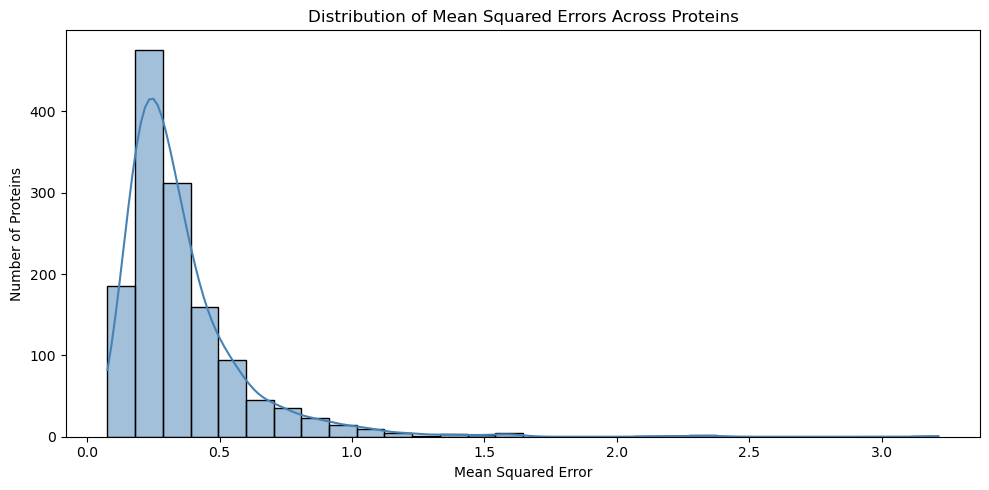

In [19]:
# Compute mean squared error for each protein across samples
protein_means = combined_df.groupby("protein")["squared_error"].mean().reset_index()
protein_means.rename(columns={"squared_error": "mean_squared_error"}, inplace=True)

# Plot the distribution
plt.figure(figsize=(10, 5))
sns.histplot(protein_means["mean_squared_error"], bins=30, kde=True, color="steelblue")

plt.title("Distribution of Mean Squared Errors Across Proteins")
plt.xlabel("Mean Squared Error")
plt.ylabel("Number of Proteins")
plt.tight_layout()
plt.show()

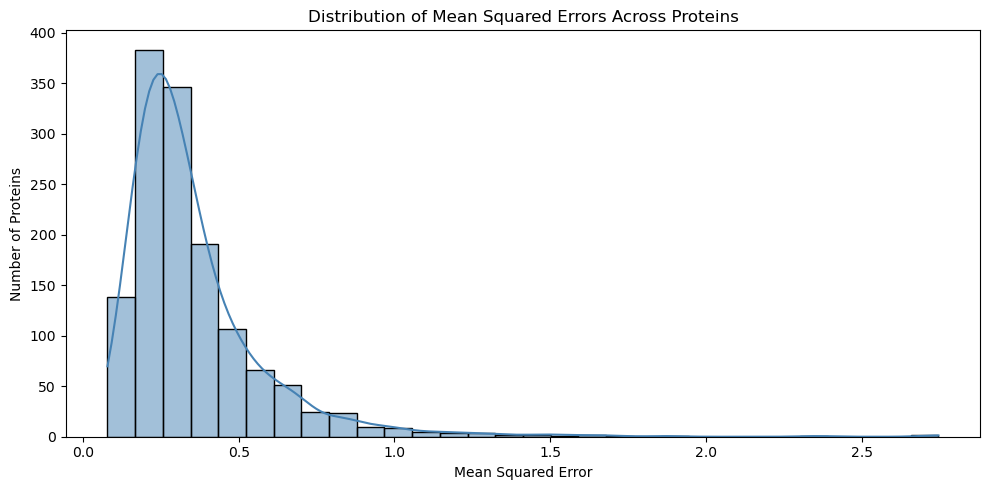

In [20]:
# Compute mean squared error for each protein across samples
protein_means = clean.groupby("protein")["squared_error"].mean().reset_index()
protein_means.rename(columns={"squared_error": "mean_squared_error"}, inplace=True)

# Plot the distribution
plt.figure(figsize=(10, 5))
sns.histplot(protein_means["mean_squared_error"], bins=30, kde=True, color="steelblue")

plt.title("Distribution of Mean Squared Errors Across Proteins")
plt.xlabel("Mean Squared Error")
plt.ylabel("Number of Proteins")
plt.tight_layout()
plt.show()

Proteins with mean_squared_error < 0.1: 6


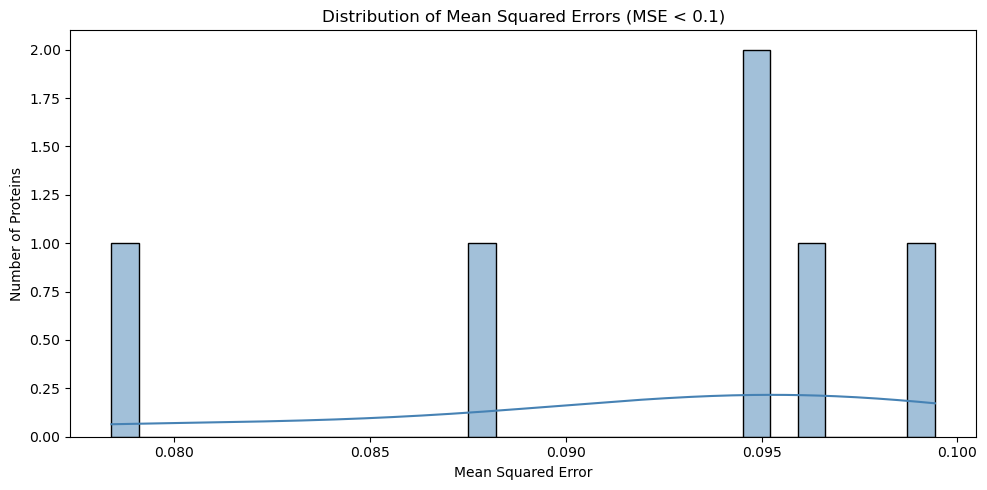


Table: Proteins with MSE < 0.100 (sorted ascending)


,protein,mean_squared_error
0,DDX1,0.078397
1,DDX3X,0.087891
2,CDK13,0.094768
3,EIF3F,0.094918
4,DDX46,0.095942
5,DDX41,0.099428


In [21]:
# MAE < 0.1
threshold = 0.1

# mask + subset for plotting
mask = protein_means["mean_squared_error"] < threshold
subset = protein_means.loc[mask, "mean_squared_error"]

print(f"Proteins with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    # --- histogram (seaborn) ---
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title(f"Distribution of Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()

    # --- table of proteins with MSE < threshold ---
    # If there's a 'protein' column, use it; otherwise, lift the index into a column.
    if "protein" in protein_means.columns:
        table = protein_means.loc[mask, ["protein", "mean_squared_error"]].copy()
    else:
        table = (
            protein_means.loc[mask, ["mean_squared_error"]]
            .reset_index()
            .rename(columns={"index": "protein"})
        )

    # sort for readability and format
    table = table.sort_values("mean_squared_error").reset_index(drop=True)
    table["mean_squared_error"] = table["mean_squared_error"].astype(float)

    # Display nicely in notebooks (falls back to print if display isn't available)
    try:
        from IPython.display import display
        print("\nTable: Proteins with MSE < {:.3f} (sorted ascending)".format(threshold))
        display(table.style.format({"mean_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Proteins with MSE < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


Proteins with mean_squared_error < 0.2: 266


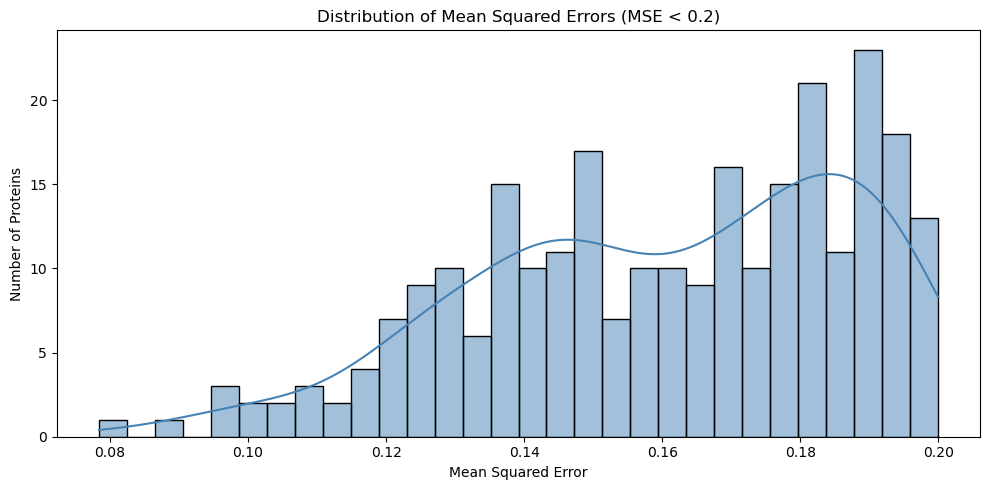

In [22]:
# Cell: MAE < 0.2
threshold = 0.2
subset = protein_means.loc[protein_means["mean_squared_error"] < threshold, "mean_squared_error"]

print(f"Proteins with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title("Distribution of Mean Squared Errors (MSE < 0.2)")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()


Proteins with mean_squared_error < 0.3: 714


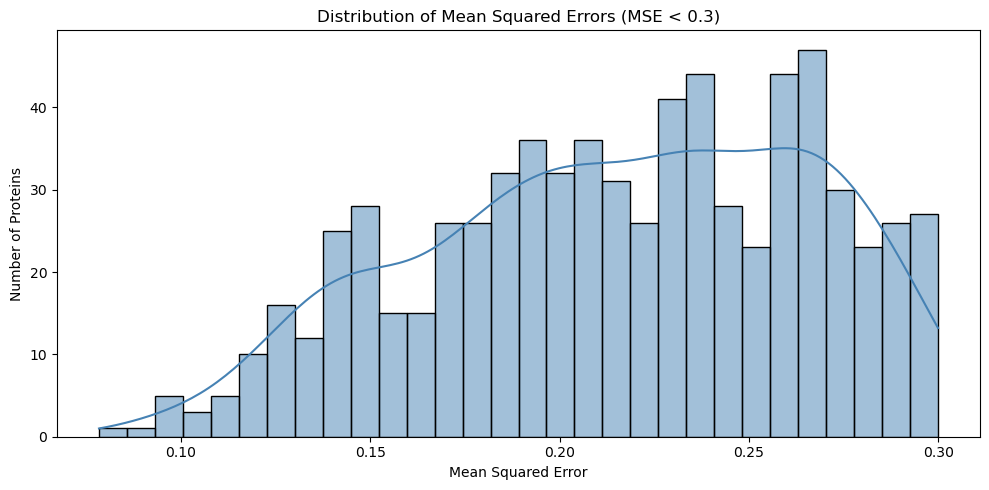

In [23]:
# Cell: MAE < 0.3
threshold = 0.3
subset = protein_means.loc[protein_means["mean_squared_error"] < threshold, "mean_squared_error"]

print(f"Proteins with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title("Distribution of Mean Squared Errors (MSE < 0.3)")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()


#### medians

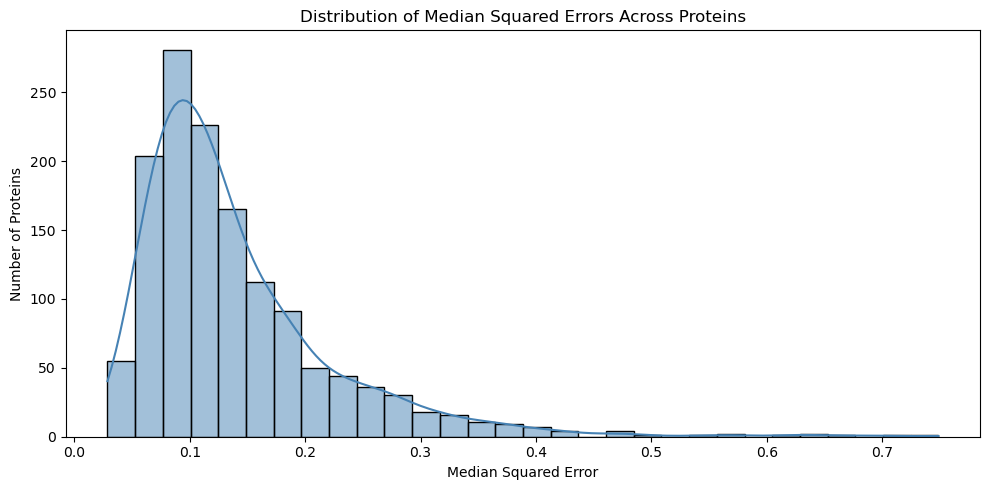

In [24]:
# Compute median squared error for each protein across samples
protein_medians = combined_df.groupby("protein")["squared_error"].median().reset_index()
protein_medians.rename(columns={"squared_error": "median_squared_error"}, inplace=True)

# Plot the distribution
plt.figure(figsize=(10, 5))
sns.histplot(protein_medians["median_squared_error"], bins=30, kde=True, color="steelblue")
plt.title("Distribution of Median Squared Errors Across Proteins")
plt.xlabel("Median Squared Error")
plt.ylabel("Number of Proteins")
plt.tight_layout()
plt.show()

Proteins with median_squared_error < 0.05: 43


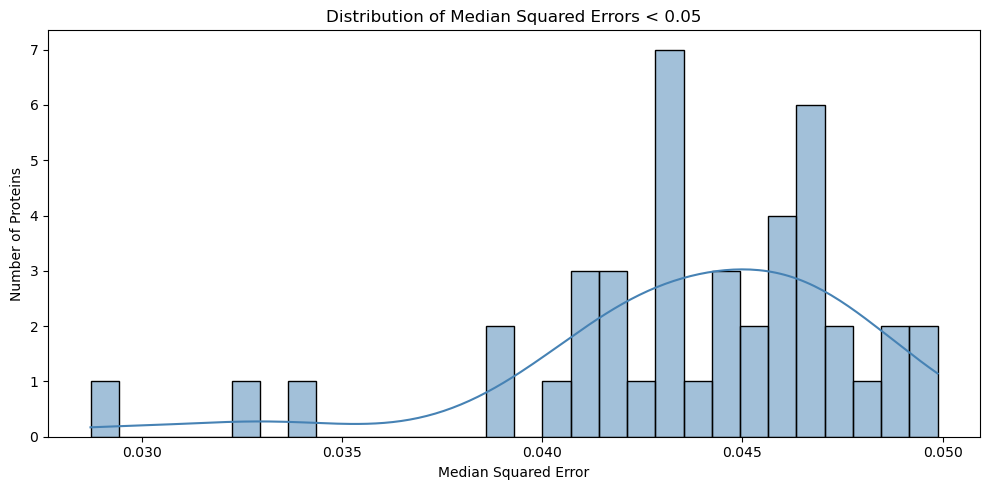

Saved CSV -> C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. xgb\model_results\exports\proteins_median_squared_error_lt_0p05_20251119-115145.csv

Table: Proteins with Median Squared Error < 0.050 (sorted ascending)


,protein,median_squared_error
0,DYNLL1,0.028721
1,DDX1,0.032415
2,EDC4,0.033876
3,CSNK2B,0.038825
4,API5,0.039210
5,DDX3X,0.040335
6,CAPZB,0.041001
7,DDX39B,0.041321
8,ANAPC7,0.041382
9,CDK13,0.041520


In [25]:
# MAE < 0.05
threshold = 0.05

# mask + subset for plotting
mask = protein_medians["median_squared_error"] < threshold
subset = protein_medians.loc[mask, "median_squared_error"]

print(f"Proteins with median_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    # --- histogram (seaborn) ---
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title(f"Distribution of Median Squared Errors < {threshold}")
    plt.xlabel("Median Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()

    # --- table of proteins with MSE < threshold ---
    # If there's a 'protein' column, use it; otherwise, lift the index into a column.
    if "protein" in protein_medians.columns:
        table = protein_medians.loc[mask, ["protein", "median_squared_error"]].copy()
    else:
        table = (
            protein_medians.loc[mask, ["median_squared_error"]]
            .reset_index()
            .rename(columns={"index": "protein"})
        )

    # sort for readability and format
    table = table.sort_values("median_squared_error").reset_index(drop=True)
    table["median_squared_error"] = table["median_squared_error"].astype(float)

    # --- SAVE TABLE ---
    from pathlib import Path
    from datetime import datetime

    out_dir = Path("exports")
    out_dir.mkdir(parents=True, exist_ok=True)

    stamp = datetime.now().strftime("%Y%m%d-%H%M%S")
    base = f"proteins_median_squared_error_lt_{threshold}".replace(".", "p")

    csv_path = out_dir / f"{base}_{stamp}.csv"
    

    table.to_csv(csv_path, index=False)
    print(f"Saved CSV -> {csv_path.resolve()}")

    # --- display nicely in notebooks ---
    try:
        from IPython.display import display
        print("\nTable: Proteins with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        display(table.style.format({"median_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Proteins with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


Proteins with median_squared_error < 0.1: 1643


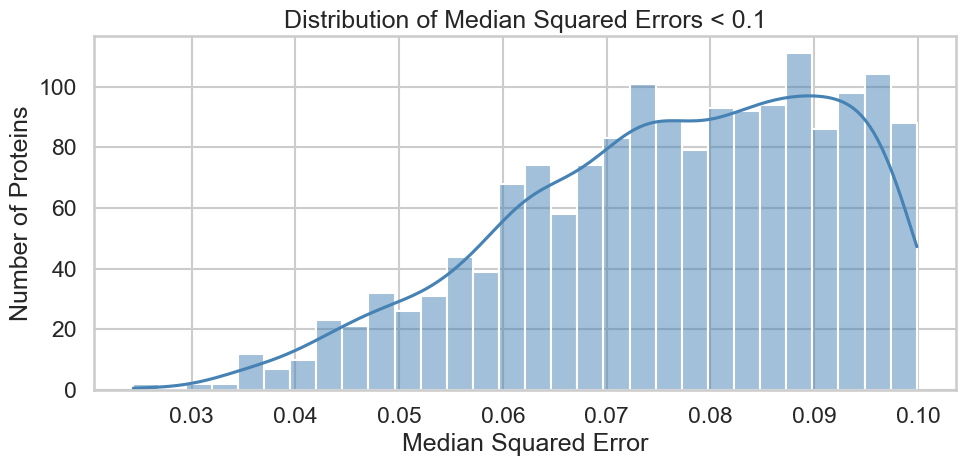

Saved CSV -> C:\Users\hp\Desktop\CPPR\Cancer-Protein-RNA-research\04. xgb\model_results\exports\proteins_median_squared_error_lt_0p1_20251113-115856.csv

Table: Proteins with Median Squared Error < 0.100 (sorted ascending)


,protein,median_squared_error
0,PPP1CC,0.024372
1,POLR2B,0.026874
2,WAPAL,0.031559
3,DYNLL1,0.031920
4,PPP1CB,0.033791
5,CSNK2B,0.034355
6,CDC42,0.034550
7,PABPC1L,0.034783
8,MIB1,0.034808
9,EFTUD2,0.035039


In [64]:
# MAE < 0.1
threshold = 0.1

# mask + subset for plotting
mask = protein_medians["median_squared_error"] < threshold
subset = protein_medians.loc[mask, "median_squared_error"]

print(f"Proteins with median_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    # --- histogram (seaborn) ---
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title(f"Distribution of Median Squared Errors < {threshold}")
    plt.xlabel("Median Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()

    # --- table of proteins with MSE < threshold ---
    # If there's a 'protein' column, use it; otherwise, lift the index into a column.
    if "protein" in protein_medians.columns:
        table = protein_medians.loc[mask, ["protein", "median_squared_error"]].copy()
    else:
        table = (
            protein_medians.loc[mask, ["median_squared_error"]]
            .reset_index()
            .rename(columns={"index": "protein"})
        )

    # sort for readability and format
    table = table.sort_values("median_squared_error").reset_index(drop=True)
    table["median_squared_error"] = table["median_squared_error"].astype(float)

    # --- SAVE TABLE ---
    from pathlib import Path
    from datetime import datetime

    out_dir = Path("exports")
    out_dir.mkdir(parents=True, exist_ok=True)

    stamp = datetime.now().strftime("%Y%m%d-%H%M%S")
    base = f"proteins_median_squared_error_lt_{threshold}".replace(".", "p")

    csv_path = out_dir / f"{base}_{stamp}.csv"
    

    table.to_csv(csv_path, index=False)
    print(f"Saved CSV -> {csv_path.resolve()}")

    # --- display nicely in notebooks ---
    try:
        from IPython.display import display
        print("\nTable: Proteins with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        display(table.style.format({"median_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Proteins with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


Proteins with median_squared_error < 0.2: 3414


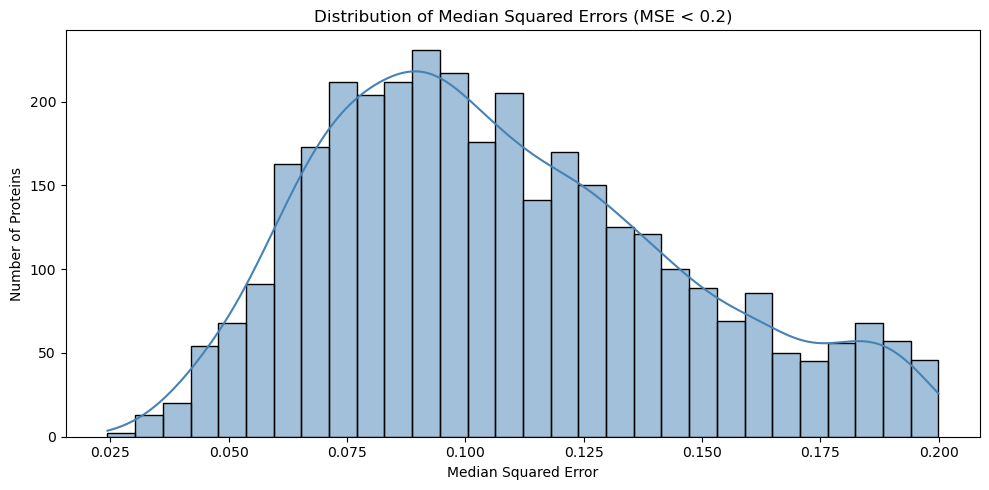

In [26]:
# Cell: MAE < 0.2
threshold = 0.2
subset = protein_medians.loc[protein_medians["median_squared_error"] < threshold, "median_squared_error"]

print(f"Proteins with median_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title("Distribution of Median Squared Errors (MSE < 0.2)")
    plt.xlabel("Median Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()

Proteins with median_squared_error < 0.3: 3841


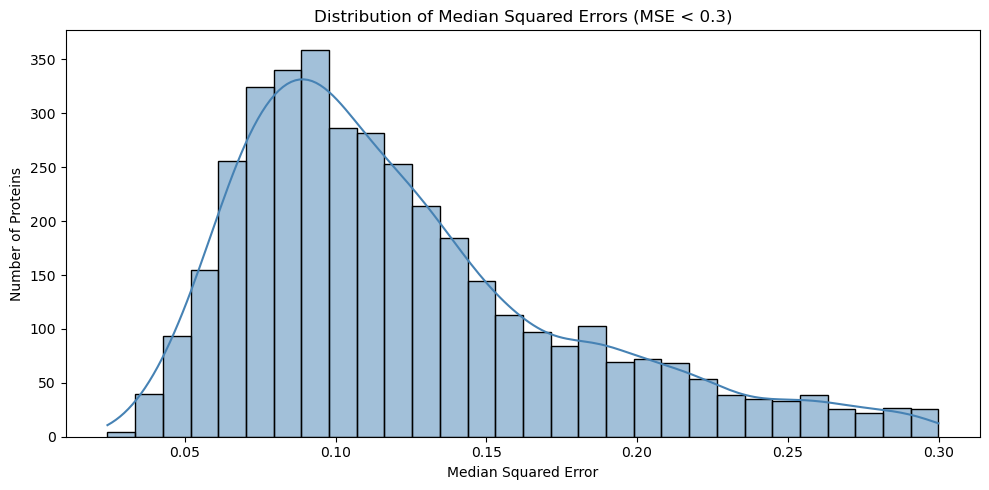

In [27]:
# Cell: MAE < 0.3
threshold = 0.3
subset = protein_medians.loc[protein_medians["median_squared_error"] < threshold, "median_squared_error"]

print(f"Proteins with median_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No proteins below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="steelblue")
    plt.title("Distribution of Median Squared Errors (MSE < 0.3)")
    plt.xlabel("Median Squared Error")
    plt.ylabel("Number of Proteins")
    plt.tight_layout()
    plt.show()


### Other per-protein plots

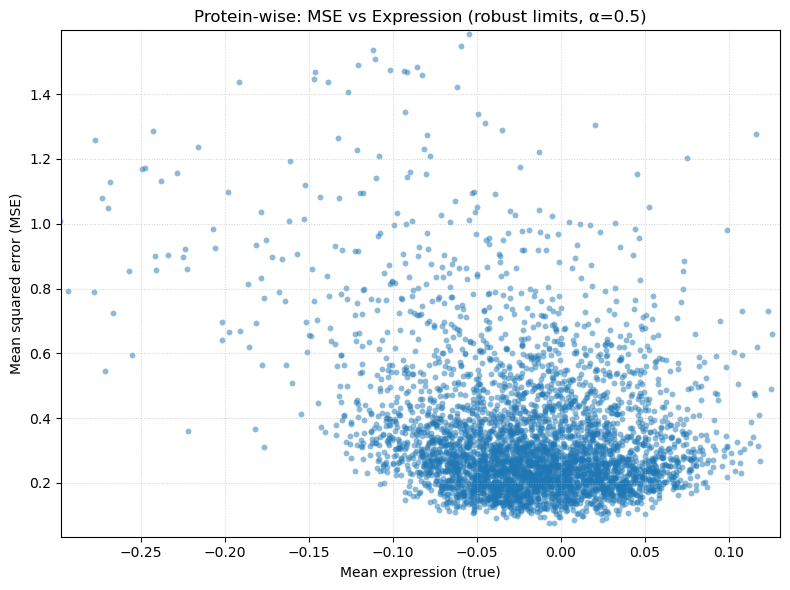

In [28]:
# MSE vs expression with robust limits and readable 1:1 line

# Recompute per-protein summary (safe if it already exists)
prot_perf = (
    combined_df.groupby('protein')
    .agg(expression=('true', 'mean'),
         mse=('squared_error', 'mean'),
         mae=('abs_error', 'mean'))
    .reset_index()
)

x = prot_perf['expression'].to_numpy()
y = prot_perf['mse'].to_numpy()

# Robust axis limits (clip to 0.5–99.5 percentiles and pad 5%)
x_lo, x_hi = np.nanpercentile(x, [0.5, 99.5])
y_lo, y_hi = np.nanpercentile(y, [0.5, 99.5])
x_pad = 0.05 * (x_hi - x_lo) if np.isfinite(x_hi - x_lo) else 1.0
y_pad = 0.05 * (y_hi - y_lo) if np.isfinite(y_hi - y_lo) else 1.0
xlim = (x_lo - x_pad, x_hi + x_pad)
ylim = (y_lo - y_pad, y_hi + y_pad)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=prot_perf, x='expression', y='mse',
    s=18, alpha=0.5, linewidth=0, edgecolor=None
)


plt.xlim(*xlim)
plt.ylim(*ylim)
plt.xlabel('Mean expression (true)')
plt.ylabel('Mean squared error (MSE)')
plt.title('Protein-wise: MSE vs Expression (robust limits, α=0.5)')
plt.grid(True, linestyle=':', linewidth=0.7, alpha=0.6)
plt.tight_layout()
plt.show()


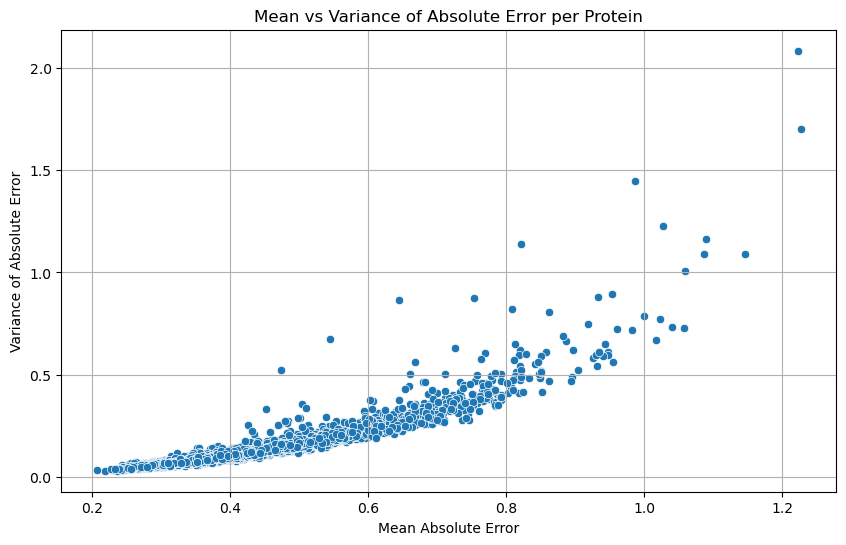

In [29]:
# Mean and variance per protein
protein_stats = combined_df.groupby('protein')['abs_error'].agg(['mean', 'var']).reset_index()

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=protein_stats, x='mean', y='var')
plt.title("Mean vs Variance of Absolute Error per Protein")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Variance of Absolute Error")
plt.grid(True)
plt.show()


#### mean error vs variance of true values

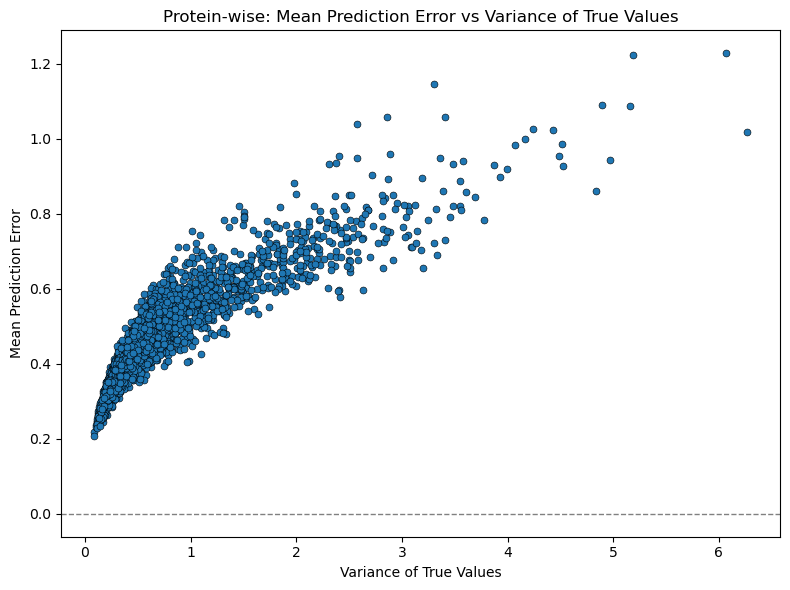

In [30]:
#Aggregate per protein 

prot_stats = (
    combined_df
    .groupby('protein')
    .agg(
        mean_error = ('abs_error', 'mean'),
        var_true   = ('true', 'var'),
    )
    .reset_index()
)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=prot_stats,
    x='var_true',
    y='mean_error',
    s=25,
    edgecolor='k'
)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Protein‑wise: Mean Prediction Error vs Variance of True Values')
plt.xlabel('Variance of True Values')
plt.ylabel('Mean Prediction Error')
plt.tight_layout()
plt.show()

### Cosine similaity 

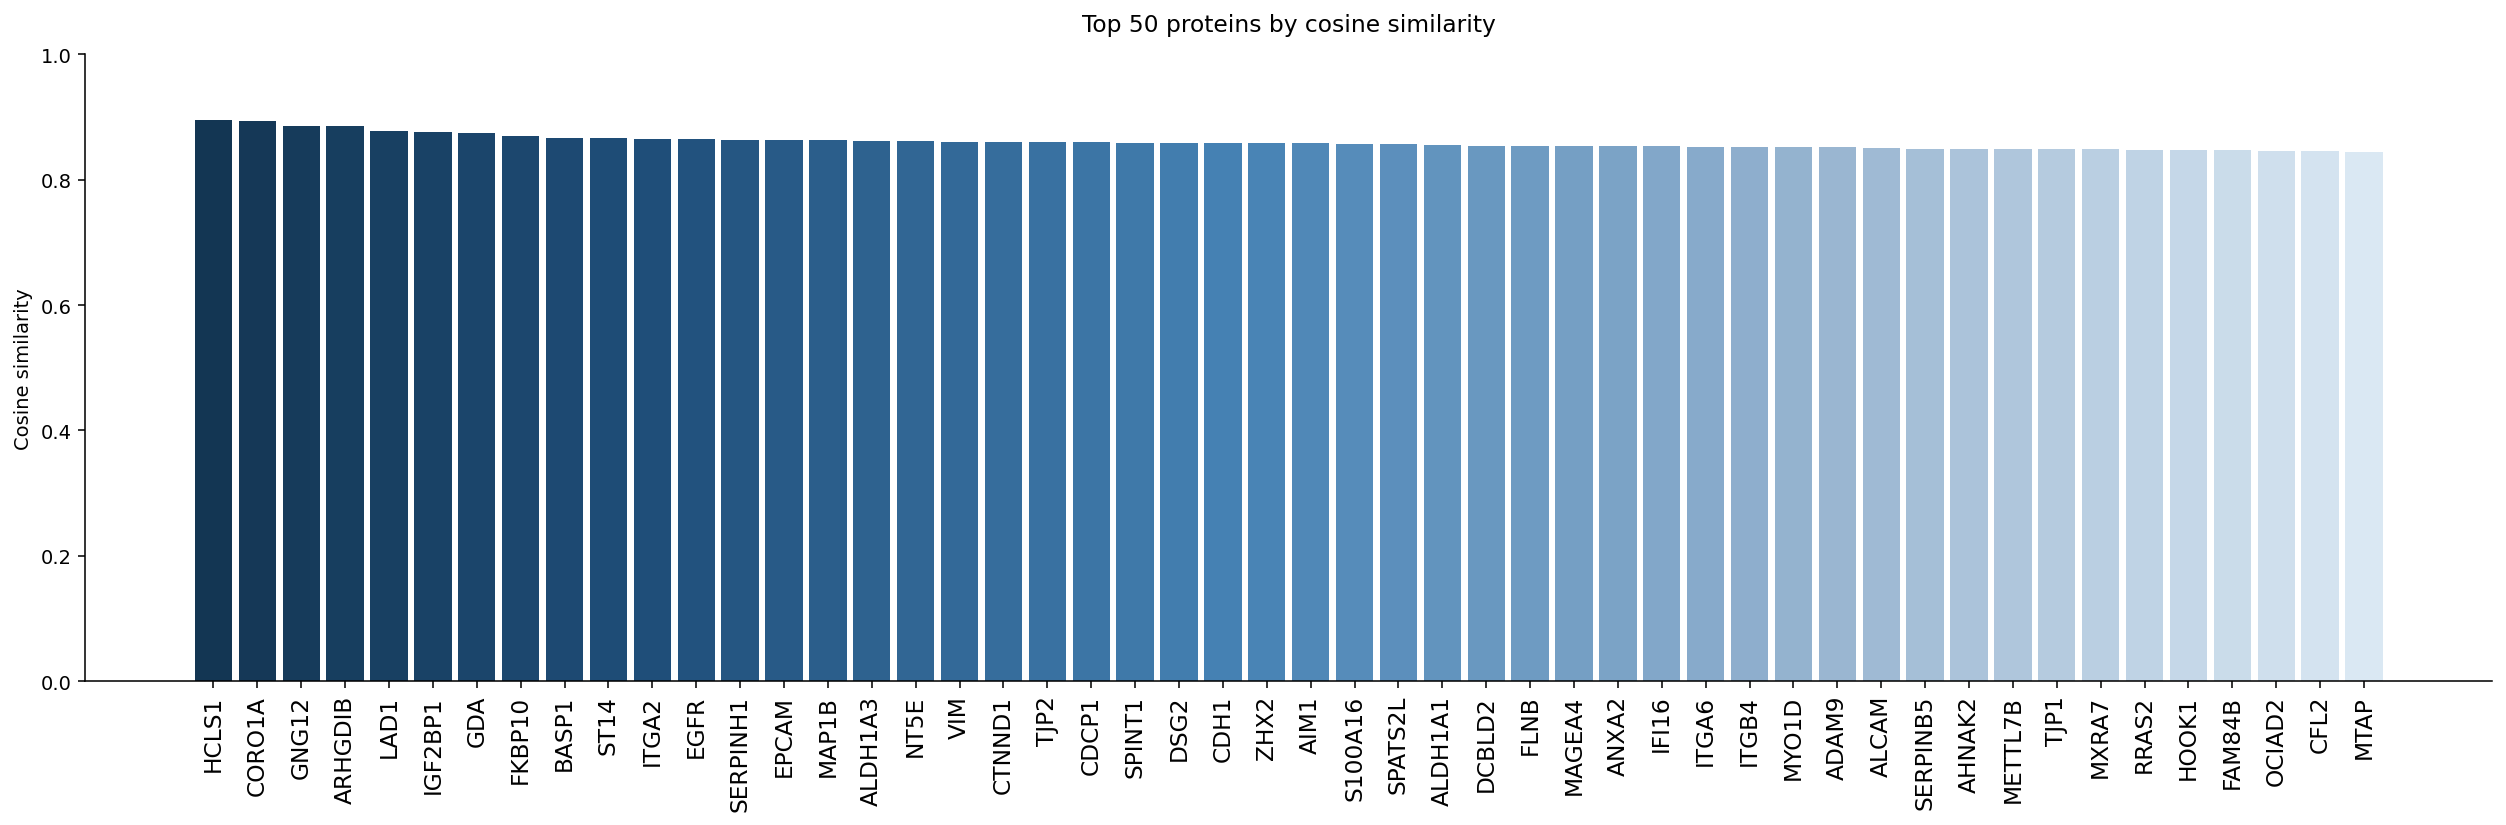

In [31]:
# Top 50, vertical bars, steelblue gradient
# prep
df = per_protein.copy()
if 'protein' in df.columns:
    df = df.set_index('protein')

df_top = (
    df[['cosine_similarity']]
    .dropna()
    .sort_values('cosine_similarity', ascending=False)
    .head(50)
)

vals   = df_top['cosine_similarity'].to_numpy()
labels = df_top.index.astype(str)

# custom steelblue gradient (deep navy → steelblue → pale)
steelblue_cmap = LinearSegmentedColormap.from_list(
    "steelblue_ramp",
    ["#0f2d45", "#1f4e79", "#4682B4", "#9ab6d1", "#e2eef7"]
)

# color by rank so the gradient flows left→right
colors = steelblue_cmap(np.linspace(0.07, 0.97, len(vals)))

fig, ax = plt.subplots(figsize=(18, 6), dpi=140)

x = np.arange(len(vals))
ax.bar(x, vals, color=colors, width=0.85)

# labels & limits
ax.set_title('Top 50 proteins by cosine similarity', pad=12)
ax.set_ylabel('Cosine similarity')
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=90, fontsize=12)
ax.set_ylim(0, max(1.0, vals.max() + 0.05))

# subtle grid & cleanup
ax.grid(False, which='both')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()


How many prteins after applying cosine similarity threshold of 0.5, 0.6, 0.7, 0.8, 0.9

In [75]:
# Summary table for cosine similarity thresholds + per-threshold tables (no saving)

df = per_protein.copy()
if "protein" in df.columns:
    df = df.set_index("protein")

if "cosine_similarity" not in df.columns:
    raise KeyError("Expected a 'cosine_similarity' column in per_protein.")

# total rows considered (robust to NaNs)
cs = df["cosine_similarity"]
total = int(cs.notna().sum())

thresholds = [0.5, 0.6, 0.7, 0.8]
rows = []

def make_table_above_threshold(frame: pd.DataFrame, thresh: float) -> pd.DataFrame:
    cs_local = frame["cosine_similarity"]
    mask = cs_local.notna() & (cs_local > thresh)
    tbl = (
        frame.loc[mask, ["cosine_similarity"]]
             .sort_values("cosine_similarity", ascending=False)
             .assign(protein=lambda d: d.index)
             .loc[:, ["protein", "cosine_similarity"]]
             .reset_index(drop=True)
    )
    return tbl

# build tables
table05 = make_table_above_threshold(df, 0.5)
table06 = make_table_above_threshold(df, 0.6)
table07 = make_table_above_threshold(df, 0.7)
table08 = make_table_above_threshold(df, 0.8)

# summary counts/percents
for t in thresholds:
    n = int((cs.notna() & (cs > t)).sum())
    pct = (n / total * 100) if total else 0.0
    rows.append({"threshold": f">{t:.1f}", "n_proteins": n, "% of total": f"{pct:.1f}%"})

summary = pd.DataFrame(rows).set_index("threshold")

print(f"Total proteins considered: {total}\n")
print(summary.to_string())

# quick confirmation of table sizes
print("\nTables created (rows):",
      f"table05={len(table05)}",
      f"table06={len(table06)}",
      f"table07={len(table07)}",
      f"table08={len(table08)}")


Total proteins considered: 4079

           n_proteins % of total
threshold                       
>0.5             2679      65.7%
>0.6             1675      41.1%
>0.7              782      19.2%
>0.8              184       4.5%

Tables created (rows): table05=2679 table06=1675 table07=782 table08=184


In [77]:
xgb05set = set(table05['protein'])
xgb06set = set(table06['protein'])
xgb07set = set(table07['protein'])
xgb08set = set(table08['protein'])

In [78]:
enet05set = set(pd.read_csv('xgb_res/proteincs05.csv')['protein'])  
enet06set = set(pd.read_csv('xgb_res/proteincs06.csv')['protein'])  
enet07set = set(pd.read_csv('xgb_res/proteincs07.csv')['protein'])  
enet08set = set(pd.read_csv('xgb_res/proteincs08.csv')['protein'])

In [79]:
total05 = len(xgb05set | enet05set)
overlap05 = len(xgb05set & enet05set)
print(f"Threshold >0.5: XGB={len(xgb05set)}, ENET={len(enet05set)}, Overlap={overlap05}, Total unique={total05}")

Threshold >0.5: XGB=2679, ENET=2842, Overlap=2194, Total unique=3327


In [80]:
total06 = len(xgb06set | enet06set)
overlap06 = len(xgb06set & enet06set)
print(f"Threshold >0.6: XGB={len(xgb06set)}, ENET={len(enet06set)}, Overlap={overlap06}, Total unique={total06}")

Threshold >0.6: XGB=1675, ENET=1912, Overlap=1403, Total unique=2184


In [81]:
total07 = len(xgb07set | enet07set)
overlap07 = len(xgb07set & enet07set)
print(f"Threshold >0.7: XGB={len(xgb07set)}, ENET={len(enet07set)}, Overlap={overlap07}, Total unique={total07}")

Threshold >0.7: XGB=782, ENET=1088, Overlap=712, Total unique=1158


In [82]:
total08 = len(xgb08set | enet08set)
overlap08 = len(xgb08set & enet08set)
print(f"Threshold >0.8: XGB={len(xgb08set)}, ENET={len(enet08set)}, Overlap={overlap08}, Total unique={total08}")

Threshold >0.8: XGB=184, ENET=390, Overlap=173, Total unique=401


In [33]:
#positive 
pos = df[df['cosine_similarity'] > 0]
len(pos)

4079

In [34]:


# total rows considered (robust to NaNs)
total = int(pos['cosine_similarity'].notna().sum())

thresholds = [0.5, 0.6, 0.7, 0.8]
rows = []
for t in thresholds:
    n = int((pos['cosine_similarity'] > t).sum())
    pct = (n / total * 100) if total else 0.0
    rows.append({"threshold": f">{t:.1f}", "n_proteins": n, "% of total": f"{pct:.1f}%"})

summary = pd.DataFrame(rows).set_index("threshold")

print(f"Total proteins considered: {total}\n")
print(summary.to_string())


Total proteins considered: 4079

           n_proteins % of total
threshold                       
>0.5             2679      65.7%
>0.6             1675      41.1%
>0.7              782      19.2%
>0.8              184       4.5%


In [35]:
df[['cosine_similarity']].describe()

,cosine_similarity
count,4079.000000
mean,0.561421
std,0.145864
min,0.061099
25%,0.461499
50%,0.564425
75%,0.668555
max,0.895017


### Comparison with baseline #to do

In [37]:
# s = pd.read_csv("res_data/pe85.csv", dtype=str)["id"]   # Series
# pe85 = s.tolist()                        # list

# Samples analysis


### Top 100 samples by mean squared error, cosine similarity, pearson correlation

In [85]:
# Per-sample metrics from combined_df → samples_df (369 rows expected)
eps = 1e-12

combined_df = combined_df.copy()

# row-wise errors
combined_df['abs_error']     = (combined_df['true'] - combined_df['predicted']).abs()
combined_df['squared_error'] = (combined_df['true'] - combined_df['predicted'])**2
combined_df['rel_error']     = combined_df['abs_error'] / (combined_df['true'].abs() + eps)

def _cos_sim(a, b):
    na = np.linalg.norm(a); nb = np.linalg.norm(b)
    denom = na * nb
    return float(np.dot(a, b) / denom) if denom > 0 else np.nan

# the column holding sample IDs (handles the space in "LOO sample")
sample_col = 'LOO sample' if 'LOO sample' in combined_df.columns else 'sample'

samples_df = (
    combined_df.groupby(sample_col, sort=False)
      .apply(lambda g: pd.Series({
          'n_proteins': len(g),
          'mae': g['abs_error'].mean(),
          'mse': g['squared_error'].mean(),
          'rmse': np.sqrt(g['squared_error'].mean()),
          'cosine_similarity': _cos_sim(g['true'].to_numpy(), g['predicted'].to_numpy()),
          'pearson_corr': g['true'].corr(g['predicted'])
      }))
      .reset_index()
      .rename(columns={sample_col: 'sample'})
)

samples_df.head()


,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr
0,MDAMB468_BREAST,4079.0,0.306244,0.179989,0.424251,0.639061,0.638649
1,SH4_SKIN,4079.0,0.301136,0.166055,0.407499,0.680645,0.680710
2,AU565_BREAST,4079.0,0.313832,0.174342,0.417542,0.728204,0.730422
3,KMRC1_KIDNEY,4079.0,0.333248,0.198764,0.445830,0.660783,0.648253
4,CAL51_BREAST,4079.0,0.276662,0.141632,0.376341,0.671847,0.668790


### Top 100 proteins by mean squared error, cosine similarity, pearson correlation

In [86]:

top100_mse     = samples_df.sort_values('mse', ascending=True).head(100)               # lower is better
top100_mae     = samples_df.sort_values('mae', ascending=True).head(100)               # optional: also show by MAE
top100_cosine  = samples_df.sort_values('cosine_similarity', ascending=False).head(100)
top100_pearson = samples_df.sort_values('pearson_corr',       ascending=False).head(100)

print("Top 100 samples by lowest MSE")
display(top100_mse)

print("\nTop 100 samples by lowest MAE")
display(top100_mae)

print("\nTop 100 samples by highest cosine similarity")
display(top100_cosine)

print("\nTop 100 samples by highest Pearson correlation")
display(top100_pearson)


Top 100 samples by lowest MSE


,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr
17,PATU8988T_PANCREAS,4079.0,0.249695,0.108918,0.330027,0.719612,0.721589
22,A2058_SKIN,4079.0,0.246641,0.112296,0.335106,0.694928,0.695950
23,SW620_LARGE_INTESTINE,4079.0,0.259437,0.120210,0.346712,0.664177,0.667364
21,A375_SKIN,4079.0,0.280056,0.132493,0.363996,0.645934,0.646516
18,JIMT1_BREAST,4079.0,0.274680,0.140186,0.374414,0.675622,0.675567
...,...,...,...,...,...,...,...
190,SNU685_ENDOMETRIUM,4079.0,0.383332,0.257017,0.506969,0.609820,0.626554
278,HS944T_SKIN,4079.0,0.370418,0.258070,0.508006,0.486173,0.486042
175,U87MG_CENTRAL_NERVOUS_SYSTEM,4079.0,0.367756,0.258285,0.508218,0.794579,0.794685
257,ISHIKAWAHERAKLIO02ER_ENDOMETRIUM,4079.0,0.383665,0.259441,0.509353,0.725693,0.725561



Top 100 samples by lowest MAE


,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr
22,A2058_SKIN,4079.0,0.246641,0.112296,0.335106,0.694928,0.695950
17,PATU8988T_PANCREAS,4079.0,0.249695,0.108918,0.330027,0.719612,0.721589
23,SW620_LARGE_INTESTINE,4079.0,0.259437,0.120210,0.346712,0.664177,0.667364
18,JIMT1_BREAST,4079.0,0.274680,0.140186,0.374414,0.675622,0.675567
4,CAL51_BREAST,4079.0,0.276662,0.141632,0.376341,0.671847,0.668790
...,...,...,...,...,...,...,...
34,SKMEL3_SKIN,4079.0,0.380804,0.243727,0.493687,0.713069,0.714376
57,NCIH1693_LUNG,4079.0,0.382492,0.251837,0.501834,0.532005,0.531912
190,SNU685_ENDOMETRIUM,4079.0,0.383332,0.257017,0.506969,0.609820,0.626554
257,ISHIKAWAHERAKLIO02ER_ENDOMETRIUM,4079.0,0.383665,0.259441,0.509353,0.725693,0.725561



Top 100 samples by highest cosine similarity


,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr
269,HEL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.401099,0.265340,0.515111,0.864188,0.863125
197,REC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.494587,0.459823,0.678103,0.838862,0.834492
187,HEL9217_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.464788,0.367693,0.606377,0.834361,0.835333
218,NUDHL1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.471100,0.384135,0.619786,0.833176,0.836510
203,CMK_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.417710,0.311644,0.558251,0.830233,0.827651
...,...,...,...,...,...,...,...
17,PATU8988T_PANCREAS,4079.0,0.249695,0.108918,0.330027,0.719612,0.721589
247,SNU449_LIVER,4079.0,0.345707,0.220386,0.469453,0.719388,0.723154
258,SNGM_ENDOMETRIUM,4079.0,0.388017,0.281433,0.530502,0.718433,0.718593
274,PC14_LUNG,4079.0,0.322168,0.187467,0.432975,0.718384,0.721279



Top 100 samples by highest Pearson correlation


,sample,n_proteins,mae,mse,rmse,cosine_similarity,pearson_corr
269,HEL_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.401099,0.265340,0.515111,0.864188,0.863125
218,NUDHL1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.471100,0.384135,0.619786,0.833176,0.836510
187,HEL9217_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.464788,0.367693,0.606377,0.834361,0.835333
197,REC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.494587,0.459823,0.678103,0.838862,0.834492
203,CMK_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.417710,0.311644,0.558251,0.830233,0.827651
...,...,...,...,...,...,...,...
171,JHUEM2_ENDOMETRIUM,4079.0,0.383821,0.281466,0.530533,0.717334,0.722585
132,SNUC1_LARGE_INTESTINE,4079.0,0.474752,0.375367,0.612672,0.721830,0.722193
366,MONOMAC6_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,4079.0,0.468337,0.361410,0.601173,0.720136,0.721895
17,PATU8988T_PANCREAS,4079.0,0.249695,0.108918,0.330027,0.719612,0.721589


In [87]:
sample_error_summary = combined_df.groupby('LOO sample').agg(
    mean_abs_error=('abs_error', 'mean'),
    std_abs_error=('abs_error', 'std'),
    mean_squared_error=('squared_error', 'mean'),
    std_squared_error=('squared_error', 'std'),
    count=('LOO sample', 'count')
).sort_values(by='mean_abs_error', ascending=False)

sample_error_summary.head()

,mean_abs_error,std_abs_error,mean_squared_error,std_squared_error,count
LOO sample,,,,,
RCHACV_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.894543,0.606449,1.167898,1.472474,4079
MOLM13_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.772734,0.597735,0.954317,1.459467,4079
IM95_STOMACH,0.707611,0.552146,0.805503,2.311568,4079
KNS42_CENTRAL_NERVOUS_SYSTEM,0.692550,0.514875,0.744656,1.120220,4079
MONOMAC1_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0.689971,0.491175,0.717254,0.934138,4079


### MSE thresholding and distributions

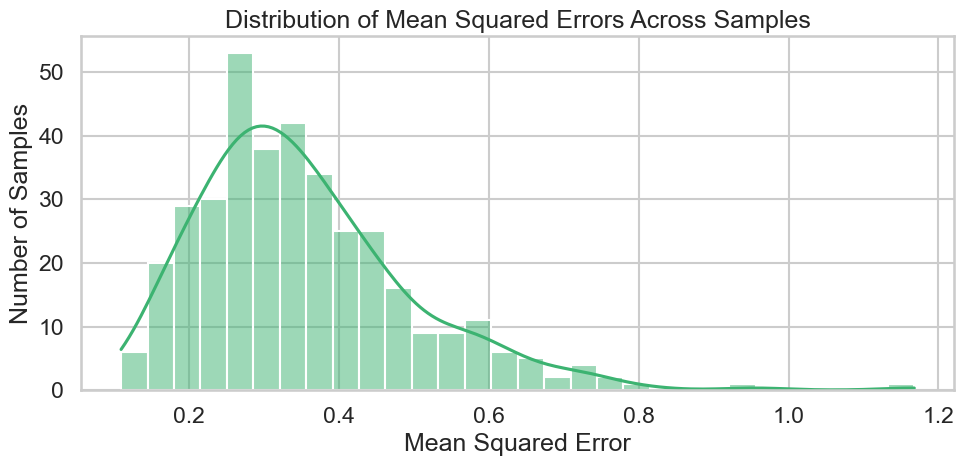

In [88]:
# Compute median absolute error across proteins for each sample
sample_means = combined_df.groupby("LOO sample")["squared_error"].mean().reset_index()
sample_means.rename(columns={"squared_error": "mean_squared_error"}, inplace=True)

# Plot
plt.figure(figsize=(10, 5))
sns.histplot(sample_means["mean_squared_error"], bins=30, kde=True, color="mediumseagreen")
plt.title("Distribution of Mean Squared Errors Across Samples")
plt.xlabel("Mean Squared Error")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


In [89]:
# Mean Squared Error per sample + threshold plot (< 0.1)

# column holding sample IDs (handles the space in "LOO sample")
sample_col = "LOO sample" if "LOO sample" in combined_df.columns else "sample"

# mean squared error across proteins for each sample
sample_means = (
    combined_df.groupby(sample_col)["squared_error"]
               .mean()
               .reset_index()
               .rename(columns={sample_col: "sample", "squared_error": "mean_squared_error"})
)

threshold = 0.1

# mask + subset for plotting
mask = sample_means["mean_squared_error"] < threshold
subset = sample_means.loc[mask, "mean_squared_error"]

print(f"Samples with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    # --- histogram (seaborn) ---
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    # --- table of samples with MSE < threshold ---
    table = (
        sample_means.loc[mask, ["sample", "mean_squared_error"]]
        .sort_values("mean_squared_error")
        .reset_index(drop=True)
    )

    try:
        from IPython.display import display
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        display(table.style.format({"mean_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


Samples with mean_squared_error < 0.1: 0
No samples below this threshold to plot.


Samples with mean_squared_error < 0.2: 43


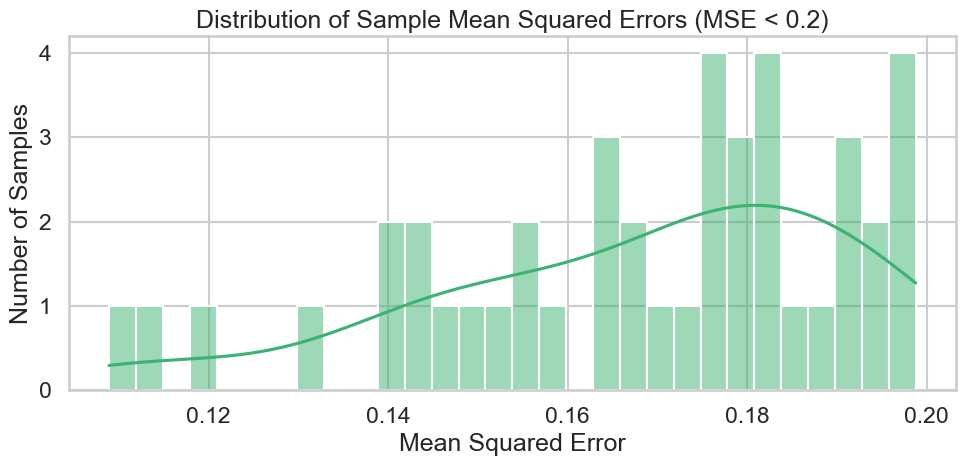


Table: Samples with MSE < 0.200 (sorted ascending)


In [90]:
threshold = 0.2

mask = sample_means["mean_squared_error"] < threshold
subset = sample_means.loc[mask, "mean_squared_error"]

print(f"Samples with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    table = (
        sample_means.loc[mask, ["sample", "mean_squared_error"]]
        .sort_values("mean_squared_error")
        .reset_index(drop=True)
    )
    try:
        from IPython.display import display
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        #display(table.style.format({"mean_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


Samples with mean_squared_error < 0.3: 152


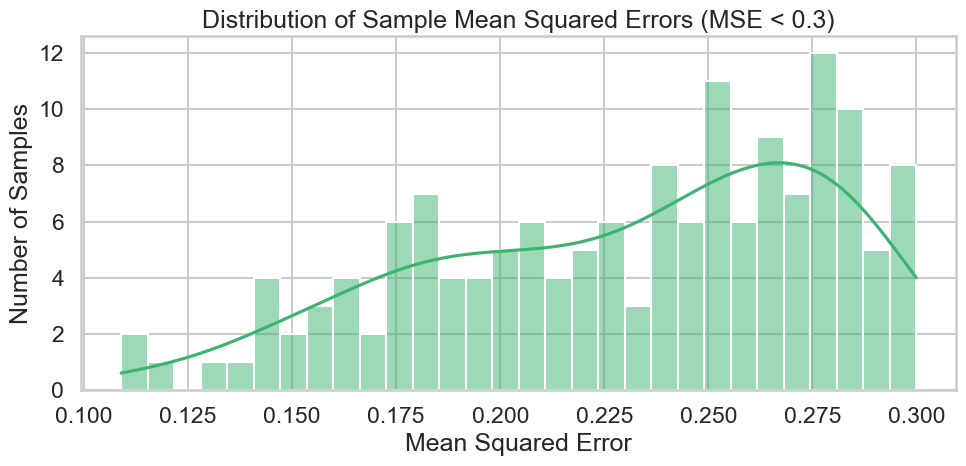


Table: Samples with MSE < 0.300 (sorted ascending)


In [91]:
threshold = 0.3

mask = sample_means["mean_squared_error"] < threshold
subset = sample_means.loc[mask, "mean_squared_error"]

print(f"Samples with mean_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    table = (
        sample_means.loc[mask, ["sample", "mean_squared_error"]]
        .sort_values("mean_squared_error")
        .reset_index(drop=True)
    )
    try:
        from IPython.display import display
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        #display(table.style.format({"mean_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with MSE < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


#### Medians

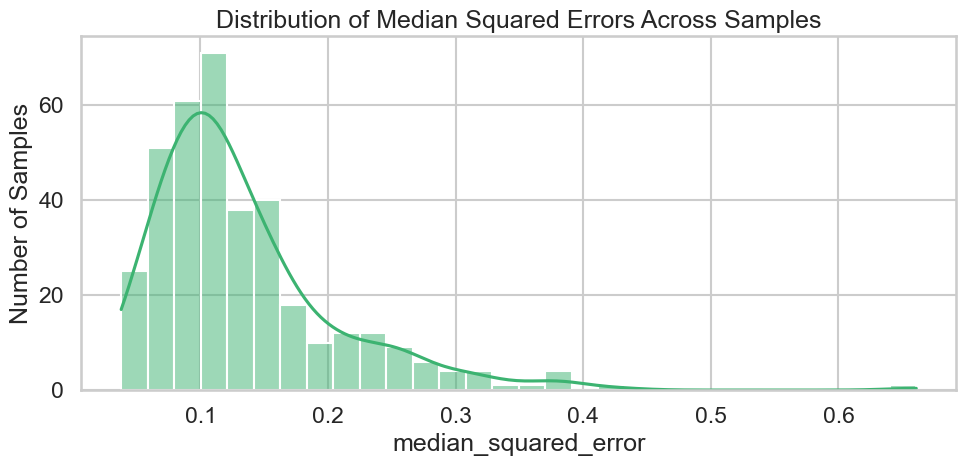

In [92]:
# Compute median absolute error across proteins for each sample
sample_medians = combined_df.groupby("LOO sample")["squared_error"].median().reset_index()
sample_medians.rename(columns={"squared_error": "median_squared_error"}, inplace=True)

# Plot
plt.figure(figsize=(10, 5))
sns.histplot(sample_medians["median_squared_error"], bins=30, kde=True, color="mediumseagreen")
plt.title("Distribution of Median Squared Errors Across Samples")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()


Samples with median_squared_error < 0.1: 136


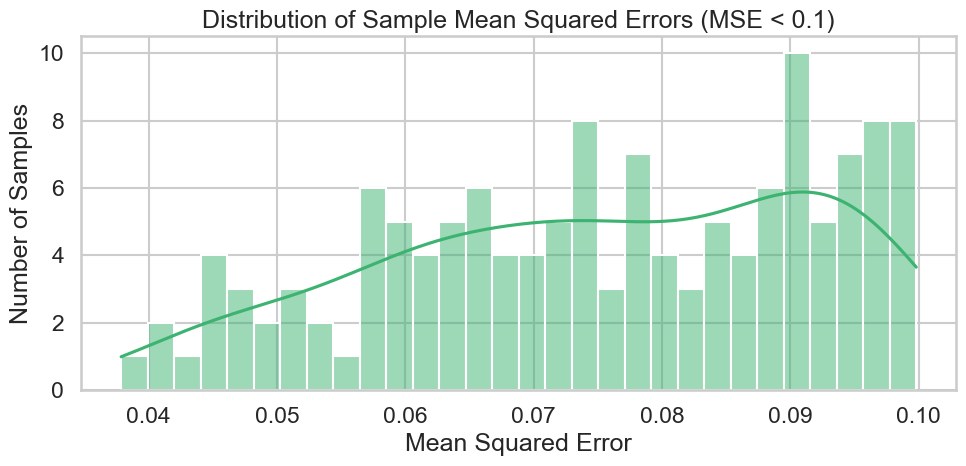


Table: Samples with Median Squared Error < 0.100 (sorted ascending)


,LOO sample,median_squared_error
0,A2058_SKIN,0.037869
1,PATU8988T_PANCREAS,0.039949
2,SW620_LARGE_INTESTINE,0.040943
3,CAL51_BREAST,0.043538
4,MELJUSO_SKIN,0.044359
5,JIMT1_BREAST,0.044586
6,HCC1954_BREAST,0.044801
7,SKHEP1_LIVER,0.045432
8,COV362_OVARY,0.046987
9,WM2664_SKIN,0.047076


In [93]:
# Mean Squared Error per sample + threshold plot (< 0.05)

# column holding sample IDs (handles the space in "LOO sample")
sample_col = "LOO sample" if "LOO sample" in combined_df.columns else "sample"

threshold = 0.1

# mask + subset for plotting
mask = sample_medians["median_squared_error"] < threshold
subset = sample_medians.loc[mask, "median_squared_error"]

print(f"Samples with median_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    # --- histogram (seaborn) ---
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    # --- table of samples with MSE < threshold ---
    table = (
        sample_medians.loc[mask, [sample_col, "median_squared_error"]]
        .sort_values("median_squared_error")
        .reset_index(drop=True)
    )

    try:
        from IPython.display import display
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        display(table.style.format({"median_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


Samples with median_squared_error < 0.05: 12


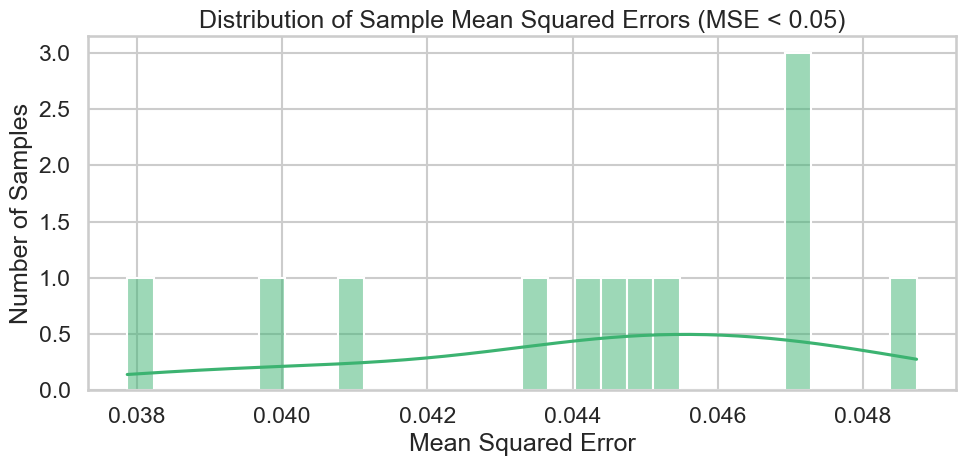


Table: Samples with Median Squared Error < 0.050 (sorted ascending)


,LOO sample,median_squared_error
0,A2058_SKIN,0.037869
1,PATU8988T_PANCREAS,0.039949
2,SW620_LARGE_INTESTINE,0.040943
3,CAL51_BREAST,0.043538
4,MELJUSO_SKIN,0.044359
5,JIMT1_BREAST,0.044586
6,HCC1954_BREAST,0.044801
7,SKHEP1_LIVER,0.045432
8,COV362_OVARY,0.046987
9,WM2664_SKIN,0.047076


In [94]:
# Mean Squared Error per sample + threshold plot (< 0.05)

# column holding sample IDs (handles the space in "LOO sample")
sample_col = "LOO sample" if "LOO sample" in combined_df.columns else "sample"

threshold = 0.05

# mask + subset for plotting
mask = sample_medians["median_squared_error"] < threshold
subset = sample_medians.loc[mask, "median_squared_error"]

print(f"Samples with median_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    # --- histogram (seaborn) ---
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    # --- table of samples with MSE < threshold ---
    table = (
        sample_medians.loc[mask, [sample_col, "median_squared_error"]]
        .sort_values("median_squared_error")
        .reset_index(drop=True)
    )

    try:
        from IPython.display import display
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        display(table.style.format({"median_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


Samples with median_squared_error < 0.1: 136


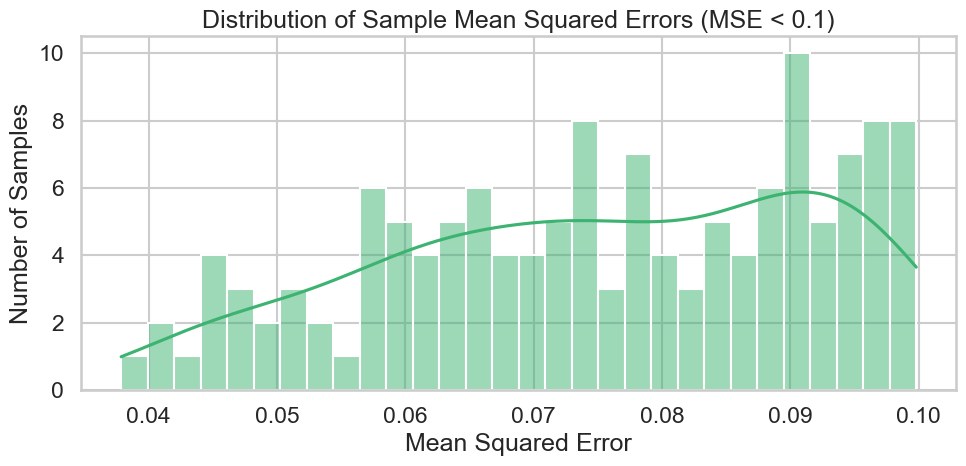


Table: Samples with Median Squared Error < 0.100 (sorted ascending)


,LOO sample,median_squared_error
0,A2058_SKIN,0.037869
1,PATU8988T_PANCREAS,0.039949
2,SW620_LARGE_INTESTINE,0.040943
3,CAL51_BREAST,0.043538
4,MELJUSO_SKIN,0.044359
5,JIMT1_BREAST,0.044586
6,HCC1954_BREAST,0.044801
7,SKHEP1_LIVER,0.045432
8,COV362_OVARY,0.046987
9,WM2664_SKIN,0.047076


In [95]:
# Mean Squared Error per sample + threshold plot (< 0.1)

# column holding sample IDs (handles the space in "LOO sample")
sample_col = "LOO sample" if "LOO sample" in combined_df.columns else "sample"

threshold = 0.1

# mask + subset for plotting
mask = sample_medians["median_squared_error"] < threshold
subset = sample_medians.loc[mask, "median_squared_error"]

print(f"Samples with median_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    # --- histogram (seaborn) ---
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    # --- table of samples with MSE < threshold ---
    table = (
        sample_medians.loc[mask, [sample_col, "median_squared_error"]]
        .sort_values("median_squared_error")
        .reset_index(drop=True)
    )

    try:
        from IPython.display import display
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        display(table.style.format({"median_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


In [96]:
xgb01s = set(table[sample_col].tolist())
len(xgb01s)

136

In [97]:
enet01s = pd.read_csv("xgb_res/samples01.csv")
enet01set = set(enet01s[sample_col].tolist())
len(enet01set)

118

In [98]:
len(enet01set & xgb01s)

108

In [99]:
len(enet01set | xgb01s)

146

Samples with median_squared_error < 0.2: 314


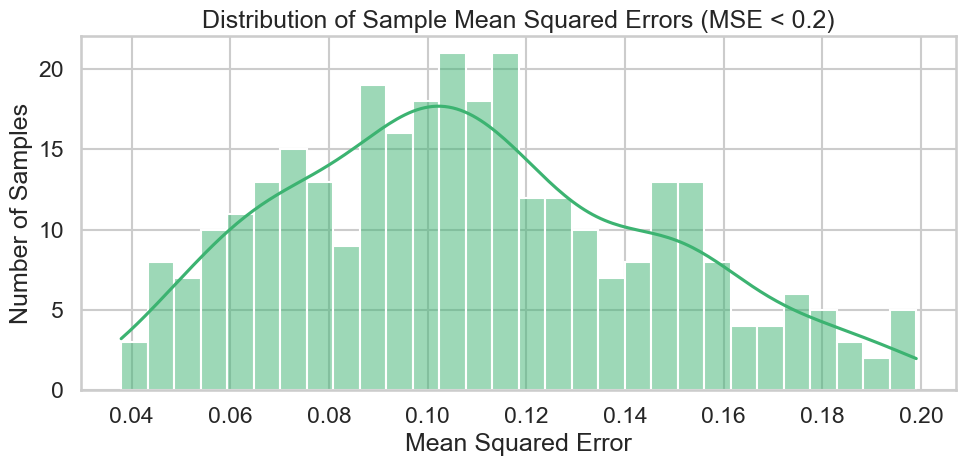


Table: Samples with Median Squared Error < 0.200 (sorted ascending)


In [100]:
threshold = 0.2

mask = sample_medians["median_squared_error"] < threshold
subset = sample_medians.loc[mask, "median_squared_error"]

print(f"Samples with median_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    table = (
        sample_medians.loc[mask, [sample_col, "median_squared_error"]]
        .sort_values("median_squared_error")
        .reset_index(drop=True)
    )
    try:
        from IPython.display import display
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        #display(table.style.format({"median_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


Samples with median_squared_error < 0.3: 354


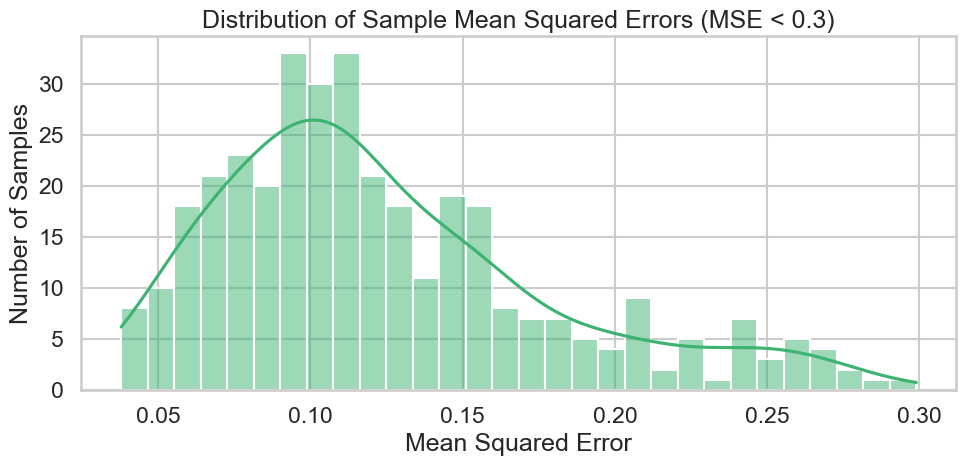


Table: Samples with Median Squared Error < 0.300 (sorted ascending)


In [101]:
threshold = 0.3

mask = sample_medians["median_squared_error"] < threshold
subset = sample_medians.loc[mask, "median_squared_error"]

print(f"Samples with median_squared_error < {threshold}: {subset.shape[0]}")

if subset.empty:
    print("No samples below this threshold to plot.")
else:
    plt.figure(figsize=(10, 5))
    sns.histplot(subset, bins=30, kde=True, color="mediumseagreen")
    plt.title(f"Distribution of Sample Mean Squared Errors (MSE < {threshold})")
    plt.xlabel("Mean Squared Error")
    plt.ylabel("Number of Samples")
    plt.tight_layout()
    plt.show()

    table = (
        sample_medians.loc[mask, [sample_col, "median_squared_error"]]
        .sort_values("median_squared_error")
        .reset_index(drop=True)
    )
    try:
        from IPython.display import display
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        #display(table.style.format({"median_squared_error": "{:.6f}"}))
    except Exception:
        print("\nTable: Samples with Median Squared Error < {:.3f} (sorted ascending)".format(threshold))
        print(table.to_string(index=False))


### Cosine similarity

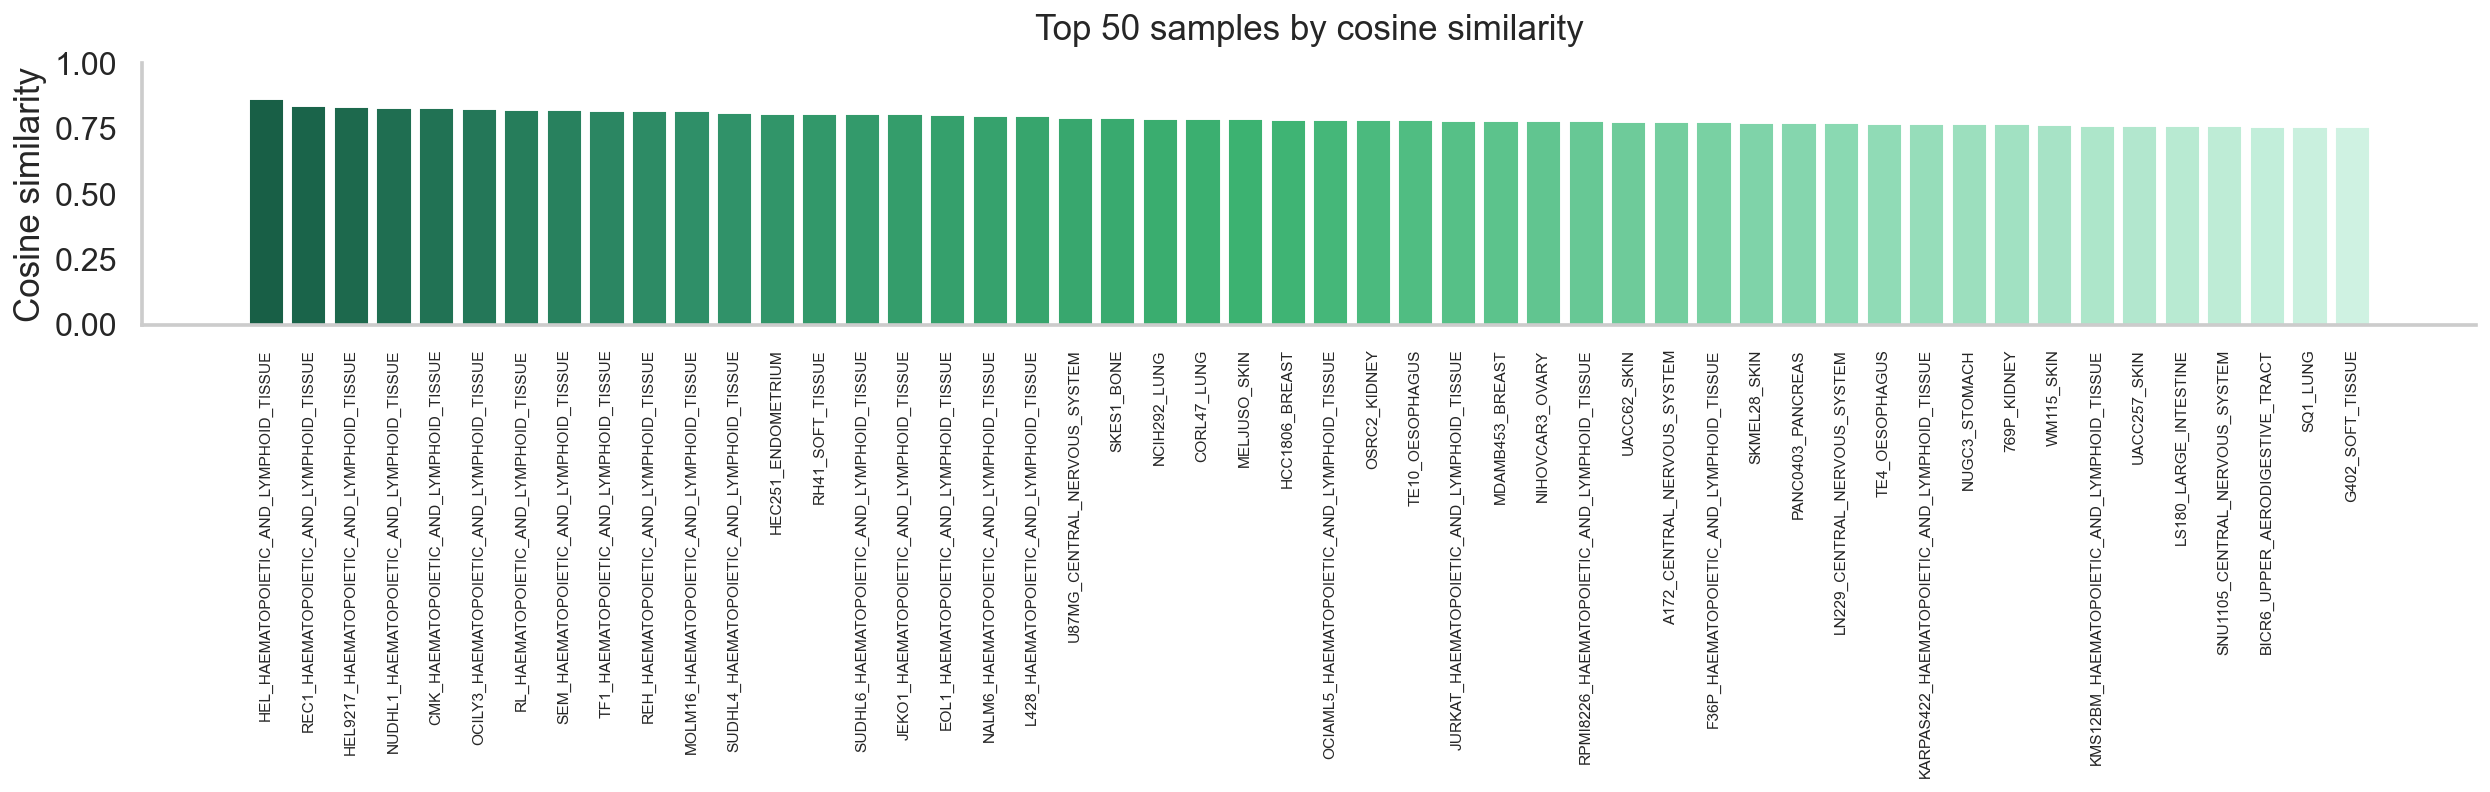

In [102]:
# Top 50 samples by cosine similarity — vertical bars, Medium SeaGreen gradient
# Build samples_df if it doesn't already exist
try:
    samples_df
except NameError:
    sample_col = "LOO sample" if "LOO sample" in combined_df.columns else "sample"
    if "squared_error" not in combined_df.columns:
        combined_df = combined_df.copy()
        combined_df["squared_error"] = (combined_df["true"] - combined_df["predicted"])**2

    samples_df = (
        clean.groupby(sample_col, sort=False)
        .apply(lambda g: pd.Series({
            "n_proteins": len(g),
            "mse": g["squared_error"].mean(),
            "cosine_similarity": _cos_sim(g["true"].to_numpy(), g["predicted"].to_numpy()),
            "pearson_corr": g["true"].corr(g["predicted"]),
        }))
        .reset_index()
        .rename(columns={sample_col: "sample"})
    )

# Sort & take top K
k = 50
df_top = (
    samples_df[["sample", "cosine_similarity"]]
    .dropna()
    .sort_values("cosine_similarity", ascending=False)
    .head(k)
)

vals   = df_top["cosine_similarity"].to_numpy()
labels = df_top["sample"].astype(str).to_numpy()

# Medium SeaGreen tonality (deep green → MediumSeaGreen → pale mint)
seagreen_cmap = LinearSegmentedColormap.from_list(
    "seagreen_ramp",
    ["#0f4d3a", "#2f8f68", "#3CB371", "#8ad9b2", "#d7f5e8"]  # tweak if we want it cooler/warmer
)
colors = seagreen_cmap(np.linspace(0.07, 0.97, len(vals)))  # smooth rank-based gradient

fig, ax = plt.subplots(figsize=(18, 6), dpi=140)
x = np.arange(len(vals))
ax.bar(x, vals, color=colors, width=0.85)

# Labels & limits
ax.set_title("Top 50 samples by cosine similarity", pad=12)
ax.set_ylabel("Cosine similarity")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=90, fontsize=8)
ax.set_ylim(0, max(1.0, vals.max() + 0.05))

# Tidy up
ax.grid(False, which='both')
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


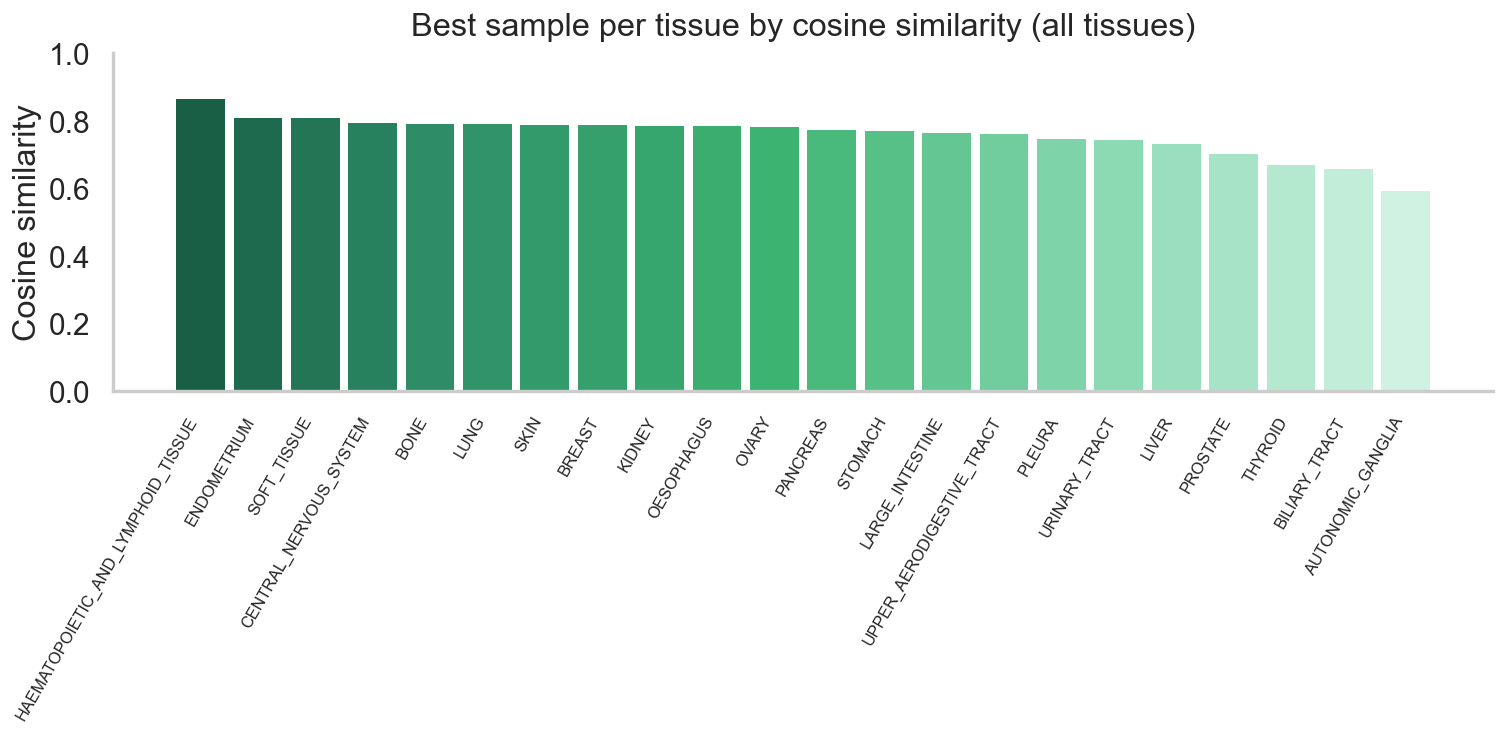

In [103]:
s = samples_df['sample'].astype(str).str.strip()
parts = s.str.split('_', n=1, expand=True)     # use n=1 as a keyword
samples_df['tissue'] = parts[1].where(parts[1].notna() & (parts[1] != ''), parts[0])

# keep one sample per tissue: the one with the highest cosine
df_best = (samples_df.dropna(subset=['tissue','cosine_similarity'])
                     .sort_values('cosine_similarity', ascending=False)
                     .drop_duplicates(subset=['tissue'], keep='first'))

# data for plotting (ALL tissues)
vals   = df_best['cosine_similarity'].to_numpy()
labels = df_best['tissue'].astype(str).to_numpy()

# Medium SeaGreen gradient (deep → light)
seagreen_cmap = LinearSegmentedColormap.from_list(
    "seagreen_ramp", ["#0f4d3a", "#2f8f68", "#3CB371", "#8ad9b2", "#d7f5e8"]
)
colors = seagreen_cmap(np.linspace(0.07, 0.97, len(vals)))

# dynamic width to fit all tissues
fig_w = max(12, 0.35 * len(vals))
fig, ax = plt.subplots(figsize=(fig_w, 6), dpi=130)

x = np.arange(len(vals))
ax.bar(x, vals, color=colors, width=0.85, edgecolor='none', linewidth=0)

ax.set_title("Best sample per tissue by cosine similarity (all tissues)", pad=10)
ax.set_ylabel("Cosine similarity")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=60, ha='right', fontsize=9)
ax.set_ylim(0, max(1.0, float(vals.max()) + 0.05))

# clean look (no grid/edges)
ax.grid(False, which='both')
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

In [115]:
# total rows considered (robust to NaNs)
total = int(samples_df['cosine_similarity'].notna().sum())

thresholds = [0.5, 0.6, 0.7, 0.8]
rows = []
for t in thresholds:
    n = int((samples_df['cosine_similarity'] > t).sum())
    pct = (n / total * 100) if total else 0.0
    rows.append({"threshold": f">{t:.1f}", "n_samples": n, "% of total": f"{pct:.1f}%"})

summary = pd.DataFrame(rows).set_index("threshold")

print(f"Total Samples considered: {total}\n")
print(summary.to_string())


Total Samples considered: 369

           n_samples % of total
threshold                      
>0.5             340      92.1%
>0.6             266      72.1%
>0.7             113      30.6%
>0.8              18       4.9%


In [105]:
# --- aggregate per tissue (MEAN)
tissue_table = (
    samples_df.dropna(subset=['tissue'])
              .groupby('tissue', as_index=False)
              .agg(n_samples=('sample', 'nunique'),
                   cosine_similarity=('cosine_similarity', 'mean'),
                   mse=('mse', 'mean'))
              .sort_values('cosine_similarity', ascending=False)
)

# --- display
try:
    display(
        tissue_table.style
            .format({'cosine_similarity': '{:.4f}', 'mse': '{:.6f}', 'n_samples': '{:d}'})
            .set_properties(subset=['tissue'], **{'font-weight': 'bold'})
    )
except Exception:
    print(tissue_table.to_string(index=False))

,tissue,n_samples,cosine_similarity,mse
6,HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,40,0.7557,0.448636
14,PLEURA,2,0.7111,0.274776
5,ENDOMETRIUM,14,0.6819,0.350890
16,SKIN,33,0.6721,0.258595
7,KIDNEY,11,0.6610,0.335129
3,BREAST,30,0.6603,0.316903
1,BILIARY_TRACT,1,0.6579,0.251167
11,OESOPHAGUS,14,0.6572,0.324140
9,LIVER,14,0.6527,0.276226
4,CENTRAL_NERVOUS_SYSTEM,13,0.6492,0.403784


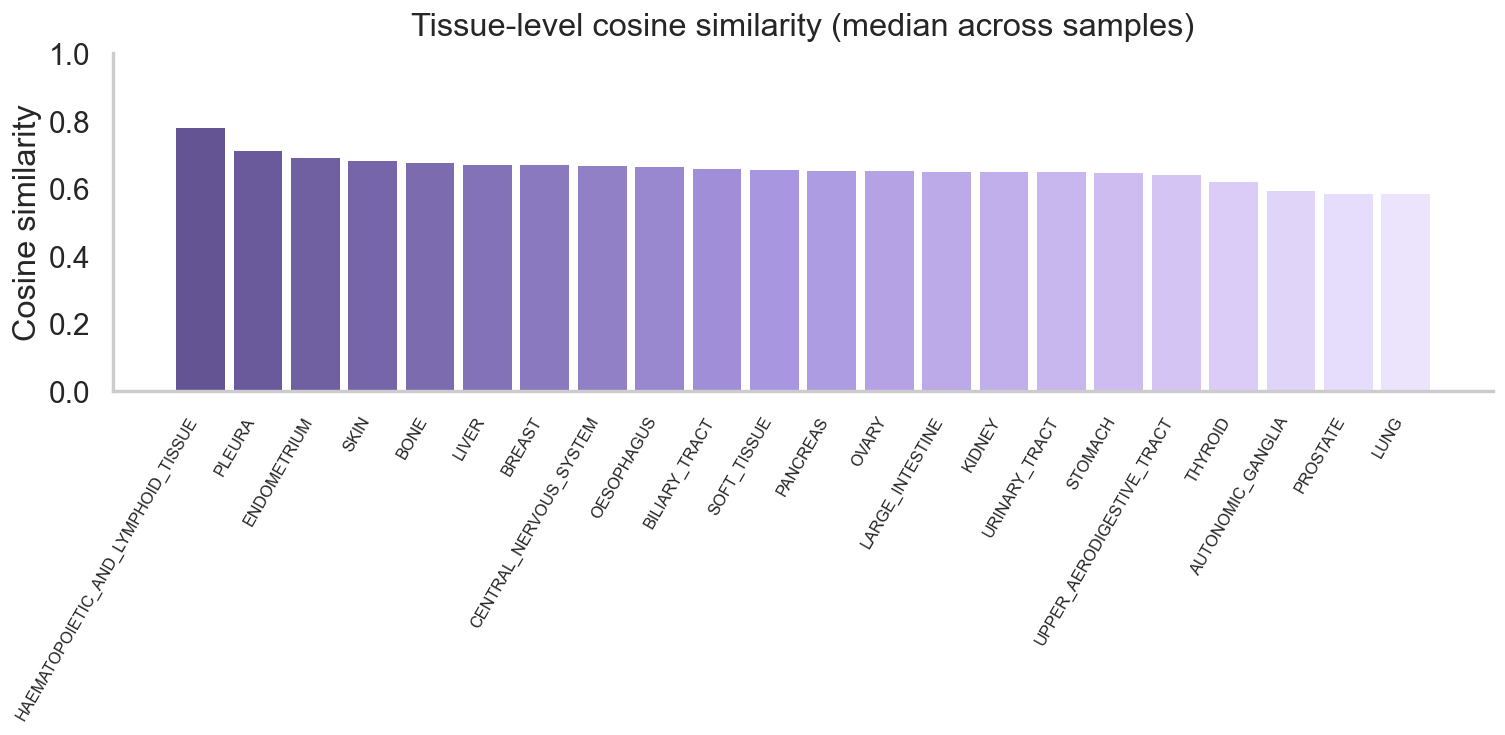

In [106]:

# --- aggregate per tissue (median; switch to 'mean' if preferred)
tissue_stats = (
    samples_df.dropna(subset=['tissue', 'cosine_similarity'])
              .groupby('tissue')
              .agg(cosine_similarity=('cosine_similarity', 'median'),
                   n_samples=('sample', 'nunique'))
              .sort_values('cosine_similarity', ascending=False)
)

vals   = tissue_stats['cosine_similarity'].to_numpy()
labels = tissue_stats.index.astype(str).to_numpy()

# Light purple (lilac) gradient
lilac_cmap = LinearSegmentedColormap.from_list(
    "lilac_ramp",
    ["#5b4b8a", "#7e6db1", "#a896e0", "#cdbbf0", "#f0e9ff"] 
)
colors = lilac_cmap(np.linspace(0.07, 0.97, len(vals)))

# dynamic width for all tissues
fig_w = max(12, 0.35 * len(vals))
fig, ax = plt.subplots(figsize=(fig_w, 6), dpi=130)

x = np.arange(len(vals))
ax.bar(x, vals, color=colors, width=0.85, edgecolor='none', linewidth=0)

ax.set_title("Tissue-level cosine similarity (median across samples)", pad=10)
ax.set_ylabel("Cosine similarity")
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=60, ha='right', fontsize=9)
ax.set_ylim(0, max(1.0, float(vals.max()) + 0.05))

ax.set_axisbelow(True)
ax.grid(False, which='both')

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Other statistical plots on Samples

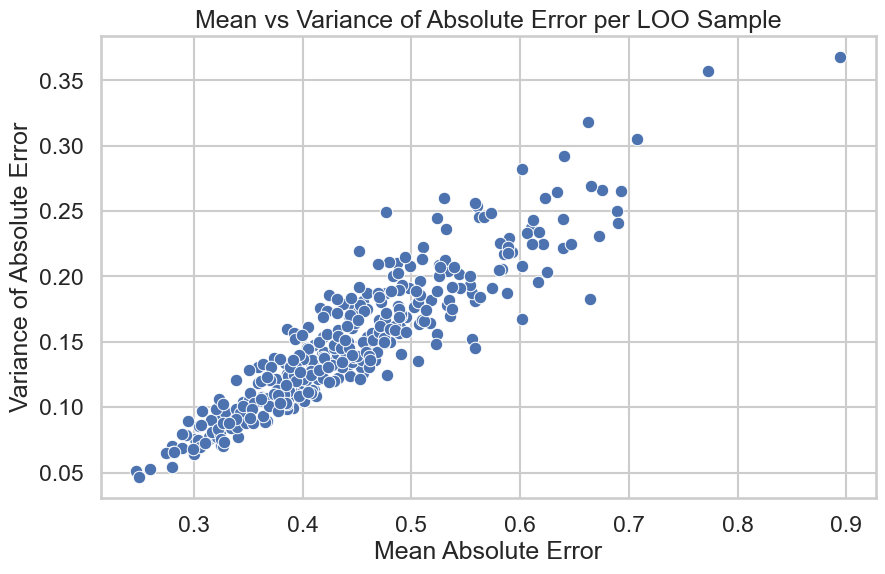

In [107]:
sample_stats = combined_df.groupby('LOO sample')['abs_error'].agg(['mean', 'var']).reset_index()

# Plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample_stats, x='mean', y='var')
plt.title("Mean vs Variance of Absolute Error per LOO Sample")
plt.xlabel("Mean Absolute Error")
plt.ylabel("Variance of Absolute Error")
plt.grid(True)
plt.show()


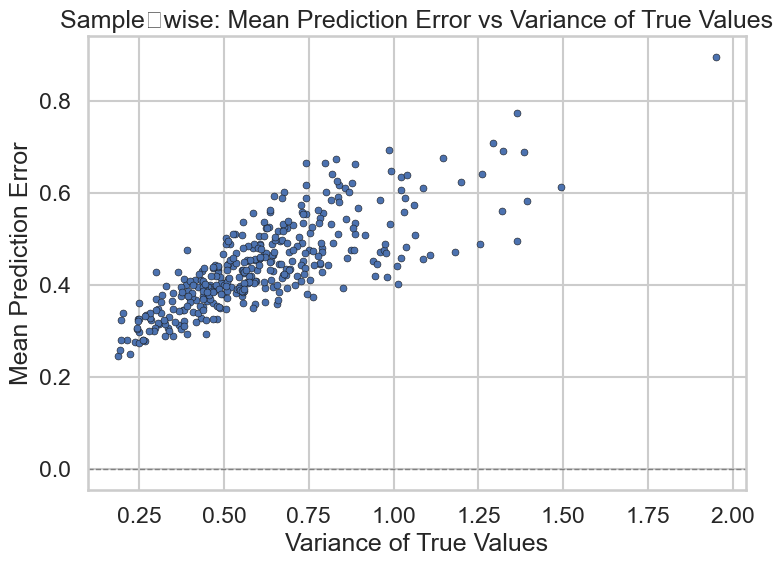

In [108]:
# Aggregate per LOO sample
sample_stats = (
    combined_df
    .groupby('LOO sample')
    .agg(
        mean_error = ('abs_error', 'mean'),
        var_true    = ('true', 'var'),
    )
    .reset_index()
)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=sample_stats,
    x='var_true',
    y='mean_error',
    s=25,
    edgecolor='k'
)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title('Sample‑wise: Mean Prediction Error vs Variance of True Values')
plt.xlabel('Variance of True Values')
plt.ylabel('Mean Prediction Error')
plt.tight_layout()
plt.show()

## Boxplot Protein and Samples

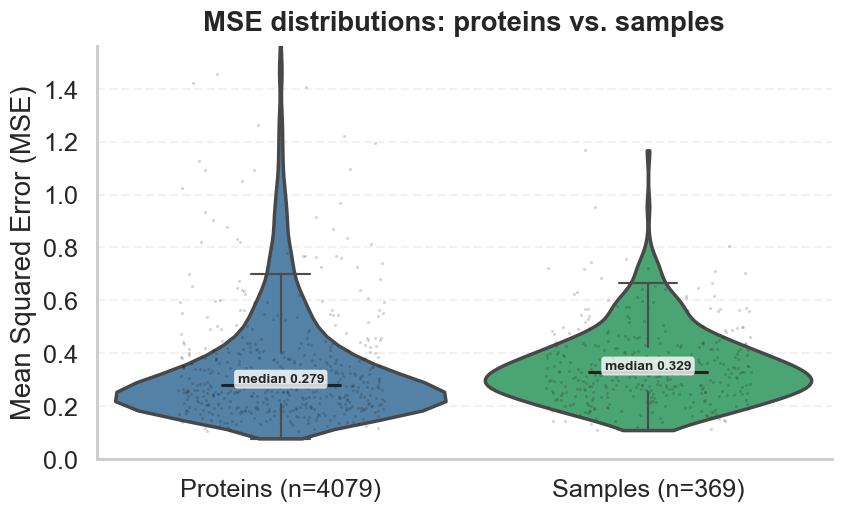

In [109]:
# Visually enhanced box/violin plot of MSE: proteins vs samples

df = combined_df.copy()
sample_col = "LOO sample" if "LOO sample" in df.columns else "sample"

# ensure squared_error exists
if "squared_error" not in df.columns:
    df["squared_error"] = (df["true"] - df["predicted"])**2

# per-group MSE
protein_mse = (
    df.groupby("protein", sort=False)["squared_error"]
      .mean()
      .reset_index()
      .rename(columns={"squared_error": "mse"})
)
sample_mse = (
    df.groupby(sample_col, sort=False)["squared_error"]
      .mean()
      .reset_index()
      .rename(columns={"squared_error": "mse", sample_col: "sample"})
)

# tidy for plotting
plot_df = pd.concat(
    [protein_mse.assign(group="Proteins")[["group", "mse"]],
     sample_mse.assign(group="Samples")[["group", "mse"]]],
    ignore_index=True
)

# aesthetics
palette = {"Proteins": "#4682B4",  # steelblue
           "Samples":  "#3CB371"}  # mediumseagreen
sns.set_theme(style="whitegrid", context="talk")

# y-limit trimmed to reduce extreme outlier pull
ymax = np.percentile(plot_df["mse"], 99.5)
ymax = float(np.clip(ymax * 1.05, 0.1, None))  # small buffer

fig, ax = plt.subplots(figsize=(8, 5), dpi=110)  # was (18, 6), 140


# violin (soft fill, no inner lines)
sns.violinplot(
    data=plot_df, x="group", y="mse",
    palette=palette, inner=None, cut=0, width=0.9, alpha=0.6, ax=ax
)

# box overlay (thin, clean)
sns.boxplot(
    data=plot_df, x="group", y="mse",
    width=0.32, showcaps=True, showfliers=False, boxprops={"facecolor": "white", "alpha": 0.9},
    medianprops={"linewidth": 2, "color": "#222"},
    whiskerprops={"linewidth": 1.4},
    capprops={"linewidth": 1.4},
    ax=ax
)

# light jittered points (subsample to keep it crisp)
pts = (
    plot_df.groupby("group", group_keys=False)
           .apply(lambda g: g.sample(n=min(500, len(g)), random_state=0))
)
sns.stripplot(
    data=pts, x="group", y="mse",
    color="k", alpha=0.18, size=2, jitter=0.28, ax=ax, zorder=1
)

# titles, labels, and counts
counts = {"Proteins": len(protein_mse), "Samples": len(sample_mse)}
ax.set_title("MSE distributions: proteins vs. samples", pad=10, weight="bold")
ax.set_xlabel("")
ax.set_ylabel("Mean Squared Error (MSE)")
ax.set_xticklabels([
    f"Proteins (n={counts['Proteins']})",
    f"Samples (n={counts['Samples']})"
])

# median annotations
meds = plot_df.groupby("group")["mse"].median().to_dict()
for i, g in enumerate(["Proteins", "Samples"]):
    m = meds[g]
    ax.text(i, m, f"median {m:.3f}", ha="center", va="bottom",
            fontsize=9, weight="bold",
            bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none", alpha=0.8))

# tidy up
ax.set_ylim(0, ymax)
ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


# MAE vs Prot- Encoding Gene correlations

In [110]:
corrs

,pearson,spearman,kendall
A2M,0.373828,0.230195,0.157938
AAAS,0.033262,0.054040,0.037045
AACS,0.475468,0.446383,0.309187
AAGAB,0.345481,0.402540,0.279094
AAK1,0.623951,0.585448,0.414043
...,...,...,...
ZWINT,0.287495,0.285369,0.193985
ZYG11B,0.327869,0.335152,0.227918
ZYX,0.685739,0.657462,0.478076
ZZEF1,0.343196,0.383925,0.260961


# Cluster-Wise analysis

In [111]:
clusters = pd.read_csv("xgb_res/protein_clusters_k3.csv")

In [112]:
clusters

,Protein,Cluster
0,A2M,3
1,AAAS,3
2,AACS,3
3,AAGAB,1
4,AAK1,2
...,...,...
5108,ZRANB2,1
5109,ZW10,3
5110,ZWILCH,1
5111,ZYX,3


Distributions

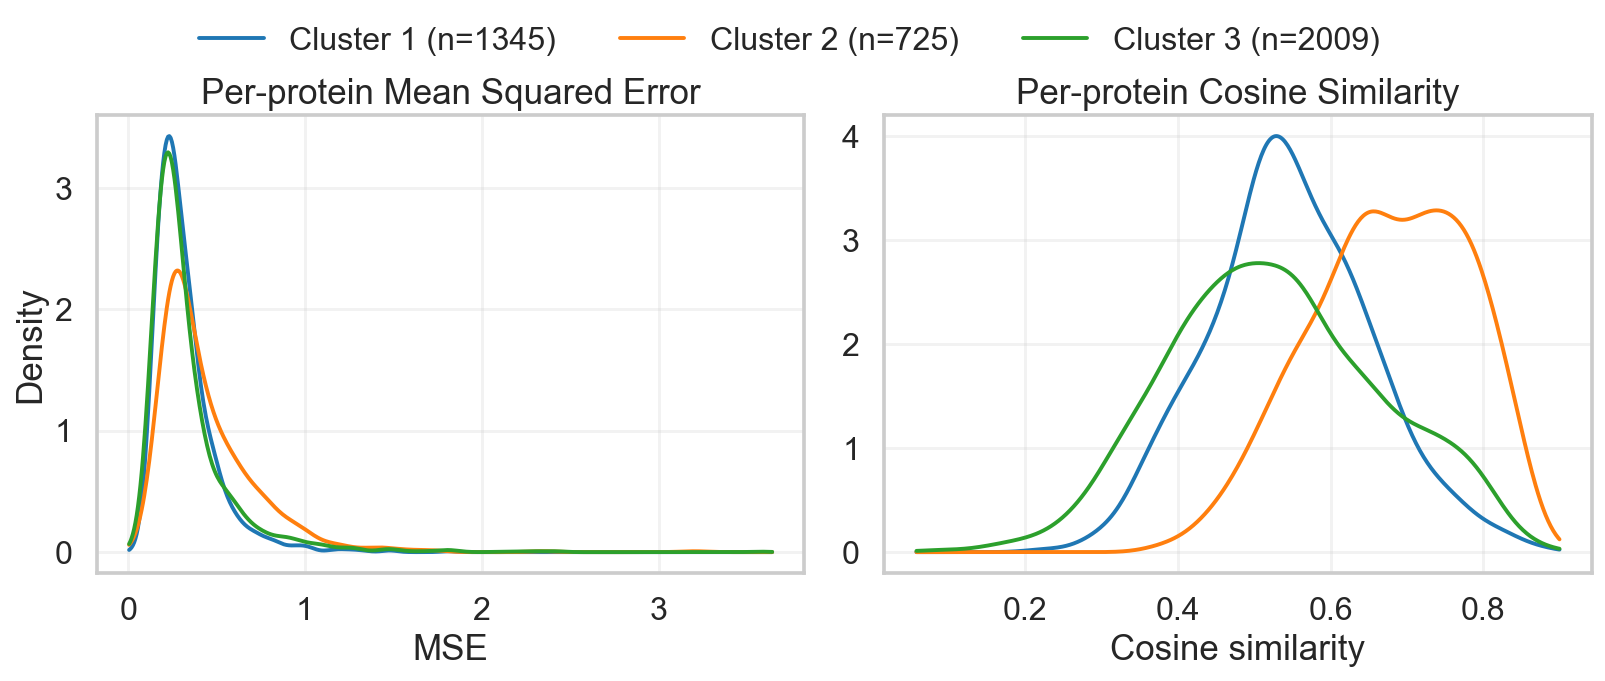

In [113]:
# Side-by-side KDEs by cluster: per-protein MSE (left) and cosine similarity (right)
# --- config
palette = {1: "#1f77b4", 2: "#ff7f0e", 3: "#2ca02c"}  # blue, orange, green

# --- helpers
def _cos_sim(a, b):
    na = np.linalg.norm(a); nb = np.linalg.norm(b)
    denom = na * nb
    return float(np.dot(a, b) / denom) if denom > 0 else np.nan

def _pad_range(x):
    x = np.asarray(x)
    xmin, xmax = float(np.min(x)), float(np.max(x))
    span = max(xmax - xmin, 1e-6)
    pad = 0.02 * span
    return xmin - pad, xmax + pad

# --- inputs
dfc = combined_df.copy()

# ensure squared_error exists
if "squared_error" not in dfc.columns:
    dfc["squared_error"] = (dfc["true"] - dfc["predicted"])**2

# --- per-protein metrics
prot_mse = (
    dfc.groupby("protein", sort=False)["squared_error"]
       .mean()
       .reset_index()
       .rename(columns={"protein": "Protein", "squared_error": "mse"})
)

prot_cos = (
    dfc.groupby("protein", sort=False)
       .apply(lambda g: _cos_sim(g["true"].to_numpy(), g["predicted"].to_numpy()))
       .reset_index(name="cosine_similarity")
       .rename(columns={"protein": "Protein"})
       .dropna(subset=["cosine_similarity"])
)

# merge with cluster mapping (expects columns: Protein, Cluster)
df_mse = prot_mse.merge(clusters[["Protein", "Cluster"]], on="Protein", how="inner")
df_cos = prot_cos.merge(clusters[["Protein", "Cluster"]], on="Protein", how="inner")

# --- x-ranges
xmin_mse, xmax_mse = _pad_range(df_mse["mse"].values)
xmin_cos, xmax_cos = _pad_range(df_cos["cosine_similarity"].values)
xr_mse = np.linspace(xmin_mse, xmax_mse, 512)
xr_cos = np.linspace(xmin_cos, xmax_cos, 512)

# --- plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), dpi=140)

# Left: MSE KDEs
for c in sorted(df_mse["Cluster"].dropna().unique()):
    vals = df_mse.loc[df_mse["Cluster"] == c, "mse"].to_numpy()
    if len(vals) >= 2:
        kde = gaussian_kde(vals)  # tweak bandwidth via bw_method=0.3 if desired
        ax1.plot(xr_mse, kde(xr_mse), lw=2, color=palette.get(c, "#333"),
                 label=f"Cluster {c} (n={len(vals)})")
    elif len(vals) == 1:  # fallback for very small groups
        ax1.axvline(vals[0], ymax=0.12, lw=2, color=palette.get(c, "#333"),
                    label=f"Cluster {c} (n=1)")

ax1.set_title("Per-protein Mean Squared Error")
ax1.set_xlabel("MSE")
ax1.set_ylabel("Density")
ax1.grid(alpha=0.25)

# Right: Cosine similarity KDEs
for c in sorted(df_cos["Cluster"].dropna().unique()):
    vals = df_cos.loc[df_cos["Cluster"] == c, "cosine_similarity"].to_numpy()
    if len(vals) >= 2:
        kde = gaussian_kde(vals)
        ax2.plot(xr_cos, kde(xr_cos), lw=2, color=palette.get(c, "#333"))
    elif len(vals) == 1:
        ax2.axvline(vals[0], ymax=0.12, lw=2, color=palette.get(c, "#333"))

ax2.set_title("Per-protein Cosine Similarity")
ax2.set_xlabel("Cosine similarity")
ax2.grid(alpha=0.25)

# Shared legend (from left subplot)
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, ncol=3, loc="upper center", frameon=False, bbox_to_anchor=(0.5, 1.01))

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


Scatterplot

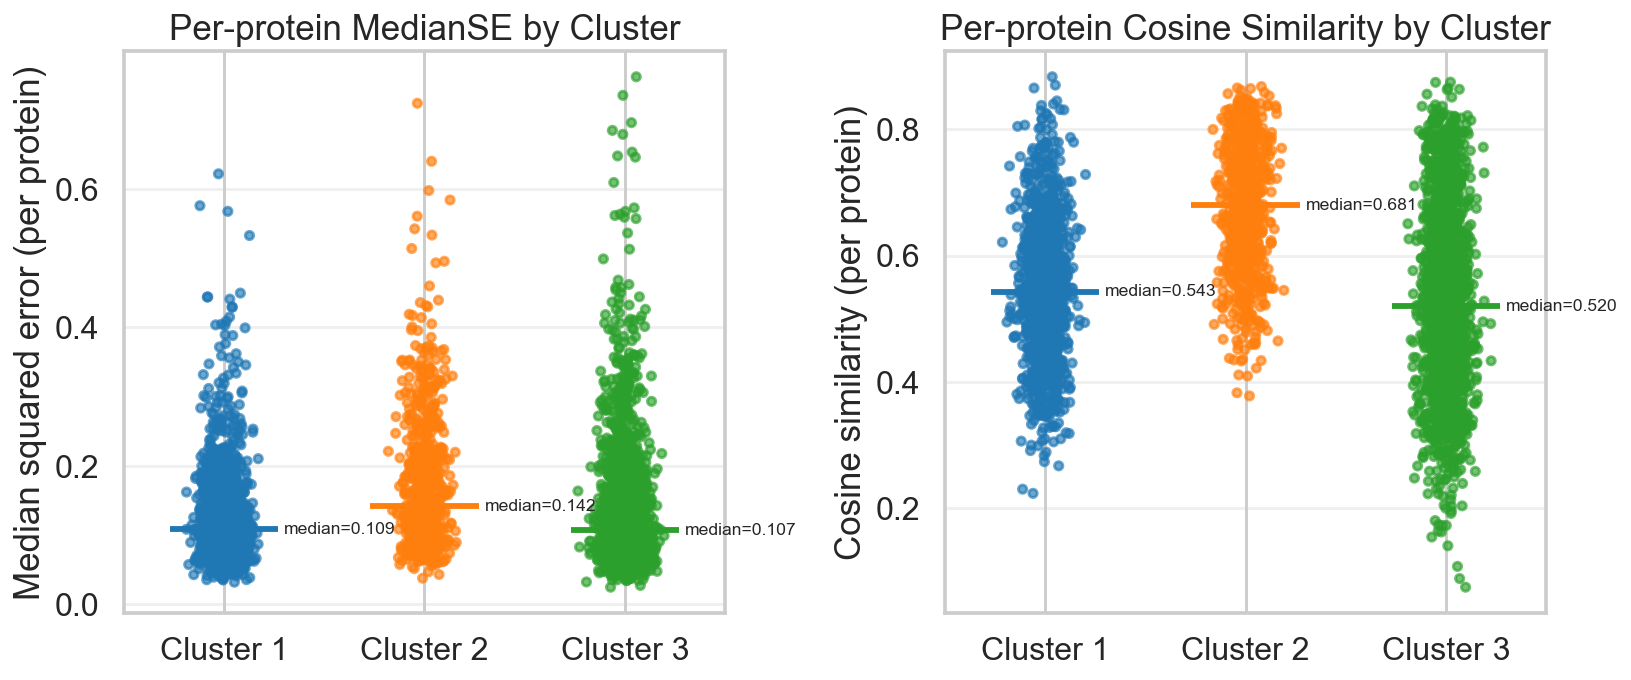

In [116]:
# Side-by-side jittered scatters by cluster: per-protein MSE (left) and cosine similarity (right)

# --- config
palette = {1: "#1f77b4", 2: "#ff7f0e", 3: "#2ca02c"}  # steelblue, orange, green

def _cos_sim(a, b):
    na = np.linalg.norm(a); nb = np.linalg.norm(b)
    denom = na * nb
    return float(np.dot(a, b) / denom) if denom > 0 else np.nan

# --- build per-protein metrics from combined_df and merge clusters
dfc = combined_df.copy()
if "squared_error" not in dfc.columns:
    dfc["squared_error"] = (dfc["true"] - dfc["predicted"])**2

# per-protein MSE
df_mse = (
    dfc.groupby("protein", sort=False)["squared_error"]
       .median()
       .reset_index()
       .rename(columns={"protein": "Protein", "squared_error": "mse"})
    .merge(clusters[["Protein", "Cluster"]], on="Protein", how="inner")
)

# per-protein cosine similarity
df_cos = (
    dfc.groupby("protein", sort=False)
       .apply(lambda g: _cos_sim(g["true"].to_numpy(), g["predicted"].to_numpy()))
       .reset_index(name="cosine_similarity")
       .rename(columns={"protein": "Protein"})
       .dropna(subset=["cosine_similarity"])
    .merge(clusters[["Protein", "Cluster"]], on="Protein", how="inner")
)

# --- helper for jittered scatter with median lines
#“Jittered” just means we add a tiny bit of random noise to each point’s position along the x-axis
# so overlapping points don’t sit exactly on top of each other. 
# It makes dense, discrete groups (like clusters 1/2/3) easier to read.
def jitter_scatter(ax, clusters_col, y_col, title, ylabel, seed=0):
    rng = np.random.default_rng(seed)
    x = clusters_col.astype(int).to_numpy()
    y = y_col.to_numpy()

    # horizontal jitter so points don't overlap
    x_jittered = x + rng.normal(0, 0.06, size=len(x))
    colors = [palette.get(int(c), "#333") for c in x]

    ax.scatter(x_jittered, y, s=18, alpha=0.65, c=colors)

    # per-cluster medians
    for c in sorted(pd.unique(clusters_col)):
        yc = y_col[clusters_col == c]
        if len(yc) == 0: 
            continue
        med = float(np.median(yc))
        ax.hlines(med, c - 0.27, c + 0.27, colors=palette.get(int(c), "#333"), linewidth=3)
        ax.text(c + 0.3, med, f"median={med:.3f}", fontsize=9, va="center")

    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(["Cluster 1", "Cluster 2", "Cluster 3"])
    ax.set_xlim(0.5, 3.5)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)

# --- plot side-by-side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2), dpi=140)

jitter_scatter(ax1, df_mse["Cluster"], df_mse["mse"],
               title="Per-protein MedianSE by Cluster",
               ylabel="Median squared error (per protein)",
               seed=0)

jitter_scatter(ax2, df_cos["Cluster"], df_cos["cosine_similarity"],
               title="Per-protein Cosine Similarity by Cluster",
               ylabel="Cosine similarity (per protein)",
               seed=1)  # different seed to vary jitter pattern

plt.tight_layout()
plt.show()
